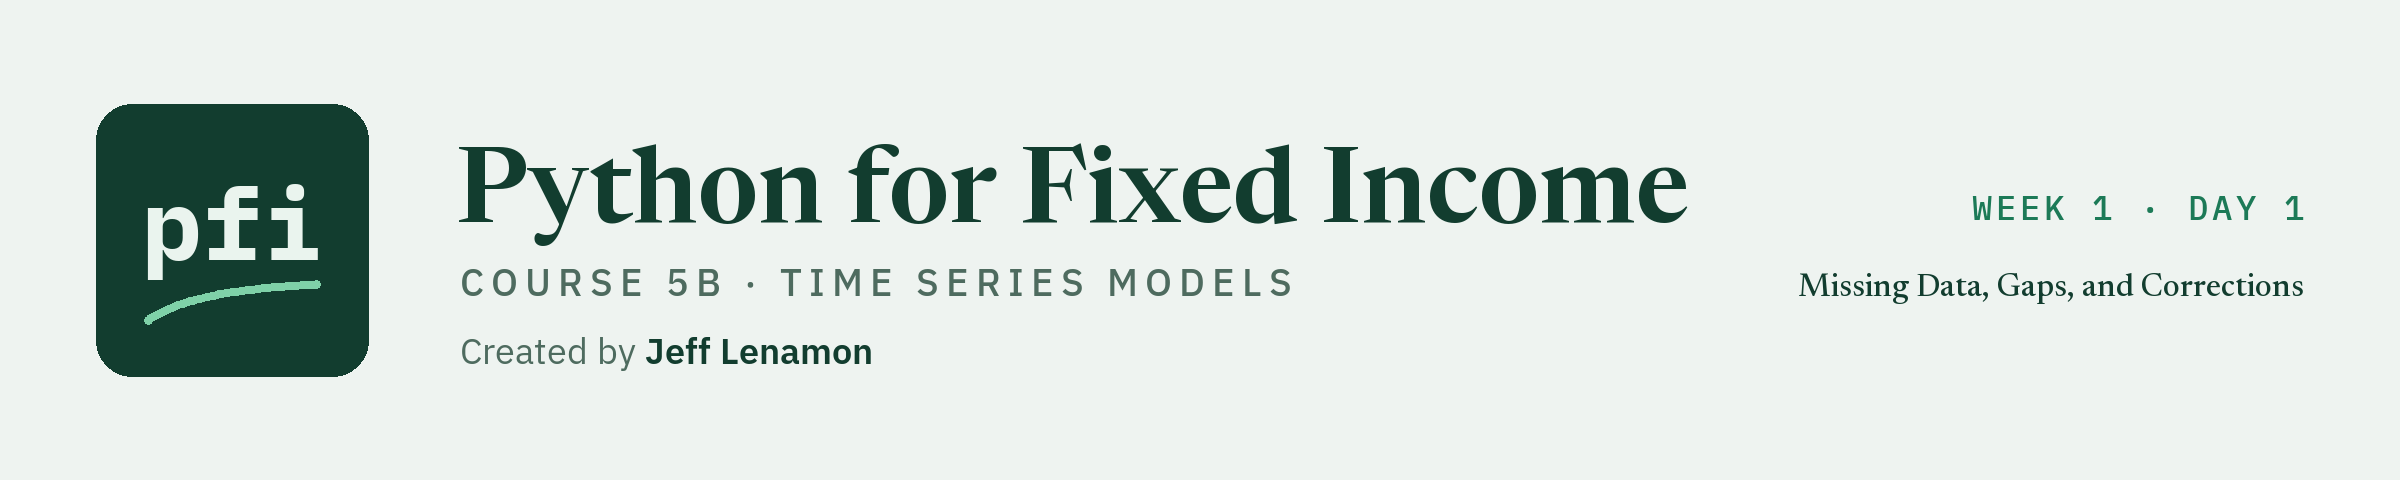

# Missing Data, Gaps, and Corrections

Week 1, Day 1. Course 5B models dated series, and it starts with the data, not the model. Today: every kind of gap a dated table can have, how to tell them apart, how to correct a wrong value with an audit trail, and which fill suits which gap.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day1/01_missing_data_gaps_and_corrections.ipynb)

Course 3 got dated data, cleaned it, and described it; it fitted no model. This course models a series: stationarity, autocorrelation, ARIMA, exponential smoothing, GARCH, and lag features for gradient boosting, every one scored walk-forward against the simplest rule there is. Every one of those models takes a table with a value on every date it is fitted on. So the course opens where every real series starts: with its gaps.

* **The data is real.** `treasury_par_yields.csv` is the U.S. Treasury's daily par yield curve, 2,940 dates from 2015-01-02 to 2026-10-02, 14 tenors, public domain. It has gaps of its own, and section 1.1 finds them first.
* **The problems are planted, and the notebook says where.** A clean public file has no outage and no wrong print, so section 1.1 makes a copy and plants them, with a seeded generator: a 20-day outage, single blank days, three wrong values, and a second source for two tenors. The real values are kept aside, so every fill can be checked against what it replaced. Nothing planted is a statement about what the Treasury published.
* **Today fits nothing.** It describes and repairs data, so it works on the whole file. From day 2 on, every model is fitted and scored only inside the development years, and a later date never reaches an earlier one.
* **Names.** A filled cell is "a filled value", with its method named; it is never called a yield the market printed. A corrected cell is in the change log. A blank the notebook leaves is "a blank, left visible".

Today you will:

1. Tell apart four kinds of missing in a dated table, and count each in the real file and the planted copy.
2. Find gaps with `isna`, a heatmap of blanks over time, and runs of blanks (`gap_runs`, `gap_report`).
3. Diagnose each gap, and decide what it needs, with a decision table.
4. Correct wrong values with `.loc`, a corrections table, `combine_first`, and a change log (`apply_corrections`), and see the trap in `DataFrame.update`.
5. Fill gaps four ways, side by side against the true values, and read every setting of `interpolate`.
6. Say which fill suits which use, and see a backfill improve a score that should not improve.
7. Stop a fill at a limit across a long outage, and keep the gap visible.

Q. Set up today's work folder: the thread settings, the seed, the Treasury file, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05b_time_series/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, statsmodels, arch, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("arch", "arch"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05b_time_series/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "arch": "8.0.0", "scikit-learn": "1.9.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5b_01_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, arch 8.0.0, scikit-learn 1.9.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5b_01_bar0tubv, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv
SEED = 42


The setup cell is the same in every Course 5B notebook, and it is Course 5's with two changes. It sets the two thread variables before numpy, pandas, statsmodels, `arch`, or LightGBM is imported, so every run adds its numbers in the same order and prints the same last digits. It checks that `statsmodels` and `arch` (the GARCH library of week 2) are installed, and stops with the install line if one is not. It prints the versions the saved outputs came from, sets `SEED = 42`, makes a fresh work folder outside the repo, and copies the Treasury file into it.

Q. Write `mlkit.py`, Course 4's complete module, unchanged. `tskit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [4]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [5]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* `mlkit.py` is Course 4's complete module, unchanged. Today starts a new module, `tskit`, which imports it: from day 2 its walk-forward splits and its past-only check score every model.
* `plotkit.py` is the series' chart and table helpers, also unchanged. It stays out of today's commits.

## 1.1 Kinds of Missing in a Dated Table

A dated table can be missing a value in four ways, and they look different in pandas:

* **An absent row.** The date is not in the index at all. A market holiday looks like this: no trading, so no row.
* **A blank cell in a present row.** The date is there, other tenors have values, and this one is `NaN`. A feed outage looks like this.
* **A series not started yet.** Every row before some date is `NaN`, because the series did not exist yet. Nothing is broken.
* **A wrong value that is present.** The cell holds a number, and the number is wrong. `isna` cannot see it.

Q. Load the Treasury file. How many rows, over what span, and which tenors?

In [6]:
# the U.S. Treasury's daily par yield curve, in percent: one row per date, one column per tenor
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
print(f"rows: {len(treasury):,}, from {treasury.index[0].date()} to {treasury.index[-1].date()}")
print(f"tenors: {list(treasury.columns)}")

rows: 2,940, from 2015-01-02 to 2026-10-02
tenors: ['1 Mo', '1.5 Month', '2 Mo', '3 Mo', '4 Mo', '6 Mo', '1 Yr', '2 Yr', '3 Yr', '5 Yr', '7 Yr', '10 Yr', '20 Yr', '30 Yr']


* 2,940 rows and 14 tenors, from the one-month bill to the 30-year bond, in percent.

Q. A row per business day would give how many rows? How many weekdays have no row?

In [7]:
# every weekday from the first date to the last, and the weekdays that have no row
weekdays = pd.bdate_range(treasury.index[0], treasury.index[-1])
absent = weekdays.difference(treasury.index)
print(f"weekdays in the span: {len(weekdays):,}; rows in the file: {len(treasury):,}; weekdays with no row: {len(absent)}")
print(f"the first five: {[str(day.date()) for day in absent[:5]]}")

weekdays in the span: 3,066; rows in the file: 2,940; weekdays with no row: 126
the first five: ['2015-01-19', '2015-02-16', '2015-05-25', '2015-07-03', '2015-09-07']


* `pd.bdate_range` lists every Monday to Friday between two dates: 3,066 of them. `difference` keeps the ones that are not in the file's index: 126 weekdays with no row. Each is an **absent row**. Section 1.3 finds out what they are.

Q. Make the planted copy: the real file with an outage, single blank days, three wrong values, and a second source planted in it. Keep the real file aside, untouched.

In [8]:
# every planted problem comes from one seeded generator, so every run plants the same ones
rng = np.random.default_rng(SEED)
planted = treasury.copy()

# 1. a 20-day outage: 20 rows in a row in which every tenor is blank (rows 1,100 to 1,399 fall in 2019 and 2020)
outage_start = int(rng.integers(1_100, 1_400))
outage_dates = planted.index[outage_start:outage_start + 20]
planted.loc[outage_dates] = np.nan

# 2. single blank days: five dates in each tenor that has a value on every date, away from the outage and the ends
full_tenors = [column for column in treasury.columns if treasury[column].notna().all()]
away = np.r_[10:outage_start - 10, outage_start + 30:len(planted) - 10]
for column in full_tenors:
    rows = rng.choice(away, size=5, replace=False)
    planted.iloc[rows, planted.columns.get_loc(column)] = np.nan

# 3. three wrong values in present rows: another tenor's yield, a yield in bp, and a slipped decimal point
wrong_5y = planted.index[int(rng.choice(np.flatnonzero(planted.index.year == 2016)))]
wrong_2y = planted.index[int(rng.choice(np.flatnonzero(planted.index.year == 2017)))]
wrong_10y = planted.index[int(rng.choice(np.flatnonzero(planted.index.year == 2022)))]
planted.at[wrong_5y, "5 Yr"] = treasury.at[wrong_5y, "30 Yr"]
planted.at[wrong_2y, "2 Yr"] = treasury.at[wrong_2y, "2 Yr"] * 100
planted.at[wrong_10y, "10 Yr"] = treasury.at[wrong_10y, "10 Yr"] * 10

# 4. a second source: the desk's own end-of-day sheet, kept for the 2 Yr and the 10 Yr from 2021 on
backup = treasury.loc["2021-01-04":, ["2 Yr", "10 Yr"]].copy()

print(f"outage: {outage_dates[0].date()} to {outage_dates[-1].date()}, {len(outage_dates)} rows")
print(f"single blank days: 5 in each of the {len(full_tenors)} full tenors")
print(f"wrong values: 5 Yr on {wrong_5y.date()}, 2 Yr on {wrong_2y.date()}, 10 Yr on {wrong_10y.date()}")
print(f"second source: {list(backup.columns)}, {len(backup):,} rows from {backup.index[0].date()}")

outage: 2019-07-03 to 2019-07-31, 20 rows
single blank days: 5 in each of the 11 full tenors
wrong values: 5 Yr on 2016-10-31, 2 Yr on 2017-03-15, 10 Yr on 2022-10-20
second source: ['2 Yr', '10 Yr'], 1,439 rows from 2021-01-04


* `treasury` stays as published: it holds the true values that every fill and every correction is checked against today. `planted` is the copy with the problems in it. In real work there is no `treasury` to check against; that is why the checks have to be designed in, and today shows which ones catch what.
* The outage ran from 2019-07-03 to 2019-07-31: 20 rows, every tenor blank. The single blank days are five dates in each of the 11 tenors that have a value on every date of the file. The three wrong values are on 2016-10-31 (5 Yr), 2017-03-15 (2 Yr), and 2022-10-20 (10 Yr).

Q. Count each kind of missing in both tables.

In [9]:
# one row per kind of missing: how it looks in a pandas table, and how many of each the two tables hold
first_valid = {column: treasury[column].first_valid_index() for column in treasury.columns}
late = [column for column in treasury.columns if first_valid[column] > treasury.index[0]]
before_start = sum(treasury[column].loc[:first_valid[column]].isna().sum() for column in late)
kinds = pd.DataFrame({
    "How it looks in pandas": ["the date is not in the index", "NaN in a row that has other values",
                               "NaN in every row before the series' first value", "a number, the wrong one"],
    "In the published file": [len(absent), int(treasury.isna().sum().sum() - before_start), int(before_start), 0],
    "In the planted copy": [len(absent), int(planted.isna().sum().sum() - before_start), int(before_start), 3],
}, index=pd.Index(["An absent row (a market holiday)", "A blank cell (an outage)", "A series not started yet",
                   "A wrong value that is present"], name="Kind of missing"))

plotkit.styled(kinds, [], "Four kinds of missing: how many cells of each in the published file and the planted copy")

,How it looks in pandas,In the published file,In the planted copy
Kind of missing,,,
An absent row (a market holiday),the date is not in the index,126,126
A blank cell (an outage),NaN in a row that has other values,0,295
A series not started yet,NaN in every row before the series' first value,"5,432","5,432"
A wrong value that is present,"a number, the wrong one",0,3


* The published file has absent rows and series not started (5,432 cells before the 1.5 Month, 2 Mo, and 4 Mo began) and no blank cell inside a series. The planted copy adds 295 blank cells and 3 wrong values. Every count of blanks below starts from this table.

## 1.2 Finding Gaps

**How it works.** A count of blanks per column says how many, and not where or how long. A dated series needs both, because one blank day and a 20-day outage need different repairs. `gap_runs` finds every **run**: it marks each row blank or not, starts a new run number wherever that mark changes, and groups the blank rows by run number. Each run gets its first and last date, its length in rows, and a kind: **before start** if it begins on the first row (the series had not started), **after end** if it reaches the last row, **inside** otherwise. `gap_report` puts one row per column on top of that: where the series starts and ends, and how many blanks sit before, inside, and after. What comes out is two small tables that a person can read, and a later check can assert on.

Q. Count the blank cells in each column of both tables with `isna().sum()`.

In [10]:
# isna() is True for each blank cell; sum() counts the Trues in each column
blank_counts = pd.DataFrame({"published file": treasury.isna().sum(), "planted copy": planted.isna().sum()})
print(blank_counts.to_string())

           published file  planted copy
1 Mo                    0            25
1.5 Month            2532          2532
2 Mo                  949           969
3 Mo                    0            25
4 Mo                 1951          1951
6 Mo                    0            25
1 Yr                    0            25
2 Yr                    0            25
3 Yr                    0            25
5 Yr                    0            25
7 Yr                    0            25
10 Yr                   0            25
20 Yr                   0            25
30 Yr                   0            25


* In the published file only three columns have blanks, and all three are the late starters. In the planted copy every full tenor has 25 blanks (the outage's 20 and five single days), and the 2 Mo has its 949 before-start rows plus the outage's 20.

Q. Write `tskit.py` with `gap_report` and `gap_runs`. Read the docstrings first.

In [11]:
%%writefile tskit.py
"""tskit: the time series pieces of Course 5B, written down and tested.

Written day by day in Python for Fixed Income, Course 5B: Time Series Models.

Conventions, the same in every function:
- A series is a pandas Series, and a frame a DataFrame, indexed by date: unique and ascending.
- Yields are in percent and changes in bp, as in the Treasury file; each docstring states its unit.
- A function that describes or repairs data never fills an earlier date from a later one unless its docstring
  says so in its first lines.
- A fitted value is for a date inside the file, from a model fitted on earlier dates only; it is never a
  statement about a date after the file ends.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # dated tables

import mlkit  # Course 4's module: its walk-forward splits and its past-only check are used from day 2


def _check_dated(index: pd.Index, name: str) -> None:
    """Stop unless the index is a DatetimeIndex that is not empty, unique, and ascending."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{name} must be indexed by date (a DatetimeIndex)")
    if len(index) == 0:
        raise ValueError(f"{name} is empty")
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError(f"{name} must have unique dates in ascending order")


def gap_report(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per column of a dated frame: where the series starts and ends, and where its values are blank.

    Input: frame, dated rows (a DatetimeIndex, unique and ascending), one column per series.
    Output: a DataFrame indexed by column name, with
      rows: the rows in the frame;
      first_valid, last_valid: the first and last dates that hold a value (NaT for a column with none);
      before_start: blank rows before first_valid (a series that had not started yet);
      blank_inside: blank cells from first_valid to last_valid (outages and gaps inside the series);
      after_end: blank rows after last_valid;
      longest_inside: the longest run of consecutive blank rows inside the series (0 when there is none).
    A date with no row at all (a market holiday) is not in the frame, so it is not counted here: compare the
    index with a calendar to find those.
    Raises ValueError for an empty frame or an index that is not dated, unique, and ascending.
    """
    _check_dated(frame.index, "frame")
    rows = []
    for column in frame.columns:
        blank = frame[column].isna().to_numpy()
        first, last = frame[column].first_valid_index(), frame[column].last_valid_index()
        if first is None:
            # no value at all: every row counts as before the start
            rows.append({"column": column, "rows": len(blank), "first_valid": pd.NaT, "last_valid": pd.NaT,
                         "before_start": len(blank), "blank_inside": 0, "after_end": 0, "longest_inside": 0})
            continue
        start, end = frame.index.get_loc(first), frame.index.get_loc(last)
        inside = blank[start:end + 1]
        runs = gap_runs(frame[column].iloc[start:end + 1]) if inside.any() else None
        rows.append({"column": column, "rows": len(blank), "first_valid": first, "last_valid": last,
                     "before_start": start, "blank_inside": int(inside.sum()), "after_end": len(blank) - 1 - end,
                     "longest_inside": int(runs["rows"].max()) if runs is not None else 0})
    return pd.DataFrame(rows).set_index("column")


def gap_runs(series: pd.Series) -> pd.DataFrame:
    """Every run of consecutive blank values in a dated series: its first and last dates and its length in rows.

    Input: series, values indexed by date (unique and ascending).
    Output: a DataFrame with one row per run, in date order, and columns
      start, end: the first and last dates of the run;
      rows: the number of blank rows in the run;
      kind: "before start" for a run on the first row (the series had not started), "after end" for a run that
      reaches the last row, and "inside" for every other run.
    With nothing blank, an empty DataFrame with the same columns. A run counts rows, not calendar days: a blank
    Friday and the blank Monday after it are one run of 2 rows.
    Raises ValueError for an empty series or an index that is not dated, unique, and ascending.
    """
    _check_dated(series.index, "series")
    blank = series.isna()
    # a new run number starts wherever blank switches between True and False
    run_number = (blank != blank.shift(fill_value=not blank.iloc[0])).cumsum()
    runs = []
    for _, run in series[blank].groupby(run_number[blank]):
        first, last = series.index.get_loc(run.index[0]), series.index.get_loc(run.index[-1])
        kind = "before start" if first == 0 else "after end" if last == len(series) - 1 else "inside"
        runs.append({"start": run.index[0], "end": run.index[-1], "rows": len(run), "kind": kind})
    return pd.DataFrame(runs, columns=["start", "end", "rows", "kind"])

Writing tskit.py


* The module docstring states the course's conventions once: dated rows, percent and bp, and a promise that nothing here fills an earlier date from a later one unless its docstring says so in its first lines.
* `_check_dated` is a private helper (it starts with `_`): both functions stop on a table that is not indexed by unique, ascending dates, because a run of blanks means nothing in a shuffled table.
* `gap_runs` finds a run with one line: `blank != blank.shift(...)` is True wherever the blank mark changes, and `cumsum` turns those changes into a run number.

Q. Write the tests: the counts, the refusals, the kinds and lengths of runs, and a series with nothing blank.

In [12]:
%%writefile test_tskit.py
"""Tests for tskit, written day by day in Course 5B. Small seeded arrays only: no data file is read."""
import numpy as np
import pandas as pd
import pytest

import tskit


def dated_frame() -> pd.DataFrame:
    """Ten business days and two seeded columns of yields in percent. Column a starts on the third day and has a
    two-day blank inside (days 5 and 6, a Friday and a Monday); column b has a value on every day."""
    rng = np.random.default_rng(42)
    dates = pd.bdate_range("2024-01-01", periods=10)
    frame = pd.DataFrame({"a": rng.normal(4.0, 0.1, 10), "b": rng.normal(4.5, 0.1, 10)}, index=dates)
    frame.iloc[:2, 0] = np.nan
    frame.iloc[4:6, 0] = np.nan
    return frame


def test_gap_report_counts():
    report = tskit.gap_report(dated_frame())
    a, b = report.loc["a"], report.loc["b"]
    assert (a["rows"], a["before_start"], a["blank_inside"], a["after_end"], a["longest_inside"]) == (10, 2, 2, 0, 2)
    assert a["first_valid"] == pd.Timestamp("2024-01-03")
    assert (b["before_start"], b["blank_inside"], b["longest_inside"]) == (0, 0, 0)


def test_gap_report_refuses_unsorted_dates():
    frame = dated_frame()
    with pytest.raises(ValueError, match="ascending"):
        tskit.gap_report(frame.iloc[::-1])
    with pytest.raises(ValueError, match="DatetimeIndex"):
        tskit.gap_report(frame.reset_index(drop=True))


def test_gap_runs_kinds_and_lengths():
    runs = tskit.gap_runs(dated_frame()["a"])
    assert runs["rows"].tolist() == [2, 2]
    assert runs["kind"].tolist() == ["before start", "inside"]
    # a Friday and the Monday after it are one run of two rows
    assert runs["start"].iloc[1] == pd.Timestamp("2024-01-05") and runs["end"].iloc[1] == pd.Timestamp("2024-01-08")
    series = dated_frame()["b"]
    series.iloc[-3:] = np.nan
    assert tskit.gap_runs(series)["kind"].tolist() == ["after end"]


def test_gap_runs_none_blank():
    runs = tskit.gap_runs(dated_frame()["b"])
    assert runs.empty and runs.columns.tolist() == ["start", "end", "rows", "kind"]

Writing test_tskit.py


* `dated_frame` makes ten business days of seeded yields with a late start and a blank Friday and Monday, small enough to check by eye. A blank Friday and the Monday after it are one run of 2 rows: runs count rows, not calendar days.

Q. Import the module and run the tests.

In [13]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import tskit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(tskit)

# the functions defined in tskit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(tskit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "tskit" and not name.startswith("_")]
print(f"tskit functions: {functions}")

tskit functions: ['gap_report', 'gap_runs']


In [14]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....                                                                     [100%]
4 passed in 2.30s



* `4 passed`. The tests read no data file: they run in a few seconds on any machine.

Q. Report every tenor of the published file. Where does each series start, and does any have a blank inside?

In [15]:
# one row per tenor of the published file
report = tskit.gap_report(treasury)
print(report.loc[["1.5 Month", "2 Mo", "4 Mo", "10 Yr"]].to_string())

           rows first_valid last_valid  before_start  blank_inside  after_end  longest_inside
column                                                                                       
1.5 Month  2940  2025-02-18 2026-10-02          2532             0          0               0
2 Mo       2940  2018-10-16 2026-10-02           949             0          0               0
4 Mo       2940  2022-10-19 2026-10-02          1951             0          0               0
10 Yr      2940  2015-01-02 2026-10-02             0             0          0               0


In [16]:
# the whole report, formatted: dates as text so the table reads cleanly
shown = report.assign(first_valid=report["first_valid"].dt.strftime("%Y-%m-%d"),
                      last_valid=report["last_valid"].dt.strftime("%Y-%m-%d"))
plotkit.styled(shown, [], "gap_report on the published file: every tenor's first and last value, and its blanks")

,rows,first_valid,last_valid,before_start,blank_inside,after_end,longest_inside
column,,,,,,,
1 Mo,"2,940",2015-01-02,2026-10-02,0,0,0,0
1.5 Month,"2,940",2025-02-18,2026-10-02,"2,532",0,0,0
2 Mo,"2,940",2018-10-16,2026-10-02,949,0,0,0
3 Mo,"2,940",2015-01-02,2026-10-02,0,0,0,0
4 Mo,"2,940",2022-10-19,2026-10-02,"1,951",0,0,0
6 Mo,"2,940",2015-01-02,2026-10-02,0,0,0,0
1 Yr,"2,940",2015-01-02,2026-10-02,0,0,0,0
2 Yr,"2,940",2015-01-02,2026-10-02,0,0,0,0
3 Yr,"2,940",2015-01-02,2026-10-02,0,0,0,0


* Every tenor ends on 2026-10-02 and none has a blank inside its own span. Three start late: the 1.5 Month on 2025-02-18, the 2 Mo on 2018-10-16, the 4 Mo on 2022-10-19. Their `before_start` counts are the 5,432 cells of section 1.1.

Q. Find the first date with a value for each late starter, with `first_valid_index`.

In [17]:
# the first date that holds a value, for each tenor that starts after the file does
for column in ["2 Mo", "4 Mo", "1.5 Month"]:
    start = treasury[column].first_valid_index()
    print(f"{column}: first value {treasury.at[start, column]:.2f} percent on {start.date()}, "
          f"{treasury.index.get_loc(start):,} rows into the file")

2 Mo: first value 2.22 percent on 2018-10-16, 949 rows into the file
4 Mo: first value 4.32 percent on 2022-10-19, 1,951 rows into the file
1.5 Month: first value 4.41 percent on 2025-02-18, 2,532 rows into the file


* `first_valid_index` returns the first index label whose value is not blank. Before that date the series did not exist in this file; the file alone cannot say why. A blank before the start is not a gap to fill: there was nothing to miss.

Q. Draw the blanks over time: for each tenor and each month, the share of rows that are blank, in the published file and in the planted copy.

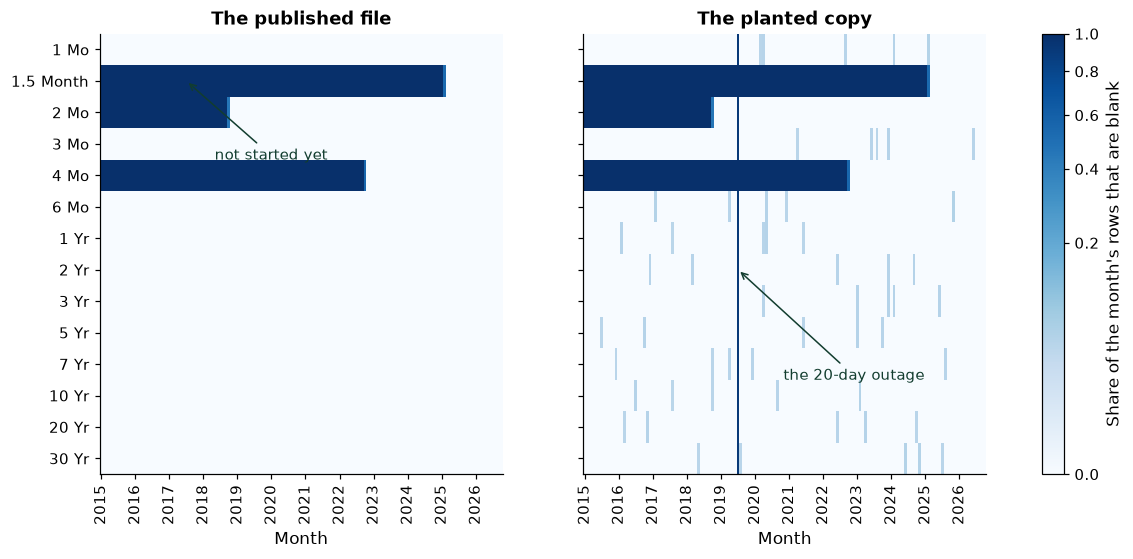

In [18]:
from matplotlib.colors import PowerNorm

# one panel per table: tenors down the side, months across, darker where more of a month's rows are blank
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, (label, frame) in zip(axes, [("The published file", treasury), ("The planted copy", planted)]):
    share = frame.isna().groupby(frame.index.to_period("M")).mean()
    # a power scale makes one blank day in a month (about 0.05) visible next to a whole blank month (1.0)
    image = ax.imshow(share.T.to_numpy(), aspect="auto", cmap="Blues", norm=PowerNorm(0.4, vmin=0, vmax=1),
                      interpolation="nearest")
    januaries = [i for i, month in enumerate(share.index) if month.month == 1]
    ax.set_xticks(januaries, [str(share.index[i].year) for i in januaries], rotation=90)
    ax.set_yticks(range(len(frame.columns)), frame.columns)
    ax.set_title(label)
    ax.set_xlabel("Month")
    ax.grid(False)
axes[1].annotate("the 20-day outage", xy=(54, 7), xytext=(70, 10.5), color=plotkit.GREEN_DARK, fontsize=10,
                 arrowprops={"arrowstyle": "->", "color": plotkit.GREEN_DARK})
axes[0].annotate("not started yet", xy=(30, 1), xytext=(40, 3.5), color=plotkit.GREEN_DARK, fontsize=10,
                 arrowprops={"arrowstyle": "->", "color": plotkit.GREEN_DARK})
fig.colorbar(image, ax=axes, label="Share of the month's rows that are blank")
plt.show()

* How to read it: one row of cells per tenor, one column per month, darker where more of the month is blank. On the left, the only dark blocks are the three late starters, solid until each series begins. On the right, the outage is a dark stripe down every tenor in July 2019, and the single blank days are the pale specks scattered through the full tenors. A heatmap like this is the first picture to draw of any dated table: it shows at once which gaps are structural and which are accidents.

Q. Find every run of blanks in every column of the planted copy, and count them by kind and length.

In [19]:
# every run of blank cells in every column of the planted copy, in one table
runs = pd.concat({column: tskit.gap_runs(planted[column]) for column in planted.columns}, names=["column", "run"])
runs = runs.reset_index(level="column").reset_index(drop=True)
summary = (runs.groupby(["kind", "rows"]).agg(runs=("column", "size"), columns=("column", lambda c: ", ".join(dict.fromkeys(c))))
           .reset_index().set_index(["kind", "rows"]))
print(f"{len(runs)} runs of blank cells")

plotkit.styled(summary, [], "Runs of blank cells in the planted copy, by kind and length in rows")

70 runs of blank cells


<styled table: Runs of blank cells in the planted copy, by kind and length in rows>

* 70 runs, of only five lengths. 55 single blank days inside the full tenors; 12 runs of 20, the outage in the 11 full tenors and in the 2 Mo; and three long runs before a start. The outage is not a run in the 4 Mo or the 1.5 Month: in July 2019 those two had not started, so its rows are part of their before-start runs.

Q. Draw the runs as bars: how many runs of each length and kind.

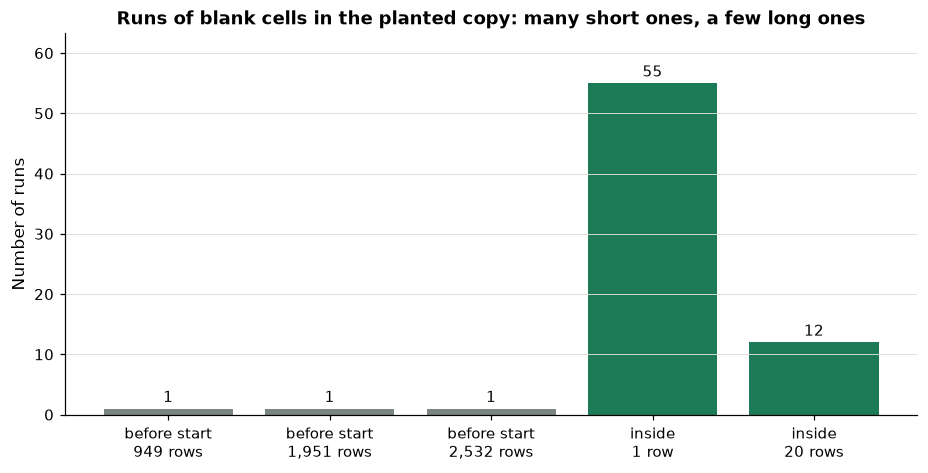

In [20]:
# one bar per (kind, length); the length is in rows, the height is the number of runs
counts = summary["runs"]
labels = [f"{kind}\n{rows:,} row{'s' if rows > 1 else ''}" for kind, rows in counts.index]
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(labels, counts.to_numpy(), color=[plotkit.GREEN if kind == "inside" else plotkit.GREY
                                                for kind, _ in counts.index])
ax.bar_label(bars, fontsize=10, padding=2)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Number of runs")
ax.set_title("Runs of blank cells in the planted copy: many short ones, a few long ones")
ax.grid(axis="x", visible=False)
plt.show()

* Green bars are gaps inside a series, which need a decision; grey bars are series that had not started, which need none. The bar to worry about is the 20-row one: a fill that is harmless across one day is not harmless across 20.

## 1.3 Diagnosing: Holiday, Outage, or Not Started Yet

A gap's kind decides its repair, so diagnose before repairing. The 126 absent weekdays come first: if they are market holidays, there is nothing to repair.

Q. Check the absent weekdays against pandas' federal holiday calendar and against Good Friday.

In [21]:
from dateutil.easter import easter
from pandas.tseries.holiday import USFederalHolidayCalendar

# the federal holidays pandas knows, and Good Friday (two days before Easter Sunday), for every year of the file
federal = USFederalHolidayCalendar().holidays(treasury.index[0], treasury.index[-1])
good_friday = pd.DatetimeIndex([pd.Timestamp(easter(year)) - pd.Timedelta(days=2) for year in range(2015, 2027)])
is_federal, is_good_friday = absent.isin(federal), absent.isin(good_friday)
other = absent[~is_federal & ~is_good_friday]
print(f"weekdays with no row: {len(absent)}")
print(f"  federal holidays in pandas' calendar: {int(is_federal.sum())}")
print(f"  Good Fridays: {int(is_good_friday.sum())}")
print(f"  neither: {len(other)}, {[str(day.date()) for day in other]}")
# the other way round: weekday federal holidays on which the file does have a row
open_days = [day for day in federal if day.dayofweek < 5 and day in treasury.index]
print(f"weekday federal holidays with a row in the file: {len(open_days)}, {[str(day.date()) for day in open_days]}")

weekdays with no row: 126
  federal holidays in pandas' calendar: 117
  Good Fridays: 8
  neither: 1, ['2018-12-05']
weekday federal holidays with a row in the file: 4, ['2017-11-10', '2021-06-18', '2021-12-31', '2023-11-10']


* 117 of the 126 absent weekdays are federal holidays in pandas' calendar and 8 are Good Fridays, which is not a federal holiday. That leaves 1, 2018-12-05: a weekday with no row that is neither. The file alone cannot say why the market had no row that day; it is a one-off absence, and it gets the same treatment as a holiday.
* The check runs the other way too. pandas' calendar moves a holiday that falls on a Saturday to the Friday before, and on 4 of those Fridays (2017-11-10, 2021-06-18, 2021-12-31, 2023-11-10) the file does have a row. A holiday calendar is a starting point for the question, not the answer: the file's own dates are. And 4 of the twelve Good Fridays in these years do have a row.

Q. How many weekdays have no row in each year?

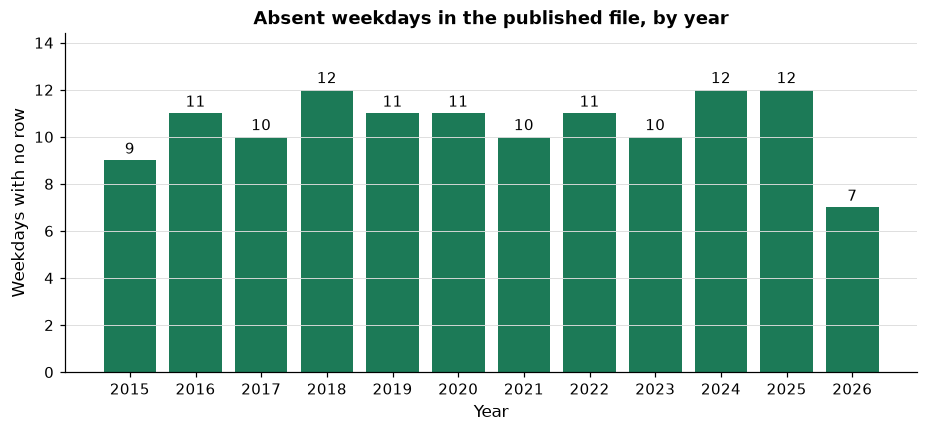

In [22]:
# absent weekdays per year: about ten a year, fewer in 2026 because the file ends in October
per_year = absent.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(per_year.index.astype(str), per_year.to_numpy(), color=plotkit.GREEN)
ax.bar_label(bars, fontsize=10, padding=2)
ax.set_ylim(0, per_year.max() * 1.2)
ax.set_xlabel("Year")
ax.set_ylabel("Weekdays with no row")
ax.set_title("Absent weekdays in the published file, by year")
ax.grid(axis="x", visible=False)
plt.show()

* Nine to 12 a year, steady across the file: the pattern of a market calendar, not of a broken feed. A feed problem would show as a cluster in one year or one month, the way the planted outage does.

Here is the decision for every kind of gap, in one table. It is the reference for the rest of the day.

In [23]:
# what each kind of gap is, how to find it, what to do, and what never to do
decision = pd.DataFrame({
    "How to find it": ["pd.bdate_range(...).difference(index)", "first_valid_index; gap_report's before_start",
                       "gap_runs: a short run inside the series", "gap_runs: a long run inside the series",
                       "a jump that comes straight back; a second source that disagrees"],
    "What it is": ["no trading, so no quote", "no series yet", "a missing quote", "a feed that was down",
                   "a quote that is there and is wrong"],
    "What to do": ["leave the date out", "start the series at its first value", "forward fill, or interpolate to describe",
                   "a second source; else leave it blank", "correct it from a source, and log it"],
    "Never": ["add the row and fill it", "backfill it", "fill a scored date from a later one",
              "interpolate across it", "overwrite it with no record"],
}, index=pd.Index(["An absent row", "Not started yet", "A short outage", "A long outage", "A wrong value"],
                  name="Kind of gap"))

plotkit.styled(decision, [], "Which repair each kind of gap needs, and what never to do")

,How to find it,What it is,What to do,Never
Kind of gap,,,,
An absent row,pd.bdate_range(...).difference(index),"no trading, so no quote",leave the date out,add the row and fill it
Not started yet,first_valid_index; gap_report's before_start,no series yet,start the series at its first value,backfill it
A short outage,gap_runs: a short run inside the series,a missing quote,"forward fill, or interpolate to describe",fill a scored date from a later one
A long outage,gap_runs: a long run inside the series,a feed that was down,a second source; else leave it blank,interpolate across it
A wrong value,a jump that comes straight back; a second source that disagrees,a quote that is there and is wrong,"correct it from a source, and log it",overwrite it with no record


* Read across a row: how to find the gap, what it is, the repair, and the one thing never to do with it. The last column is where most real errors come from: a holiday turned into a filled row, a late series backfilled to look complete, an outage drawn as a straight line.

## 1.4 Correcting Wrong Values

**How it works.** A wrong value is the one kind of missing that `isna` cannot find, so it is found by its shape or by a second source: a print that jumps and comes straight back, or a value that disagrees with another file. Once found, it is corrected from a source, and the correction is written down. A **corrections table** holds one row per cell: the date, the column, the new value, and where it came from. `apply_corrections` writes each row into a copy of the table and returns, beside the copy, a **change log**: date, column, old value, new value, source, for every cell that changed. The settings that matter are what goes in the table (a value, or `NaN` to blank a cell) and the source text, which is what an auditor reads. What comes out is the corrected table and a log that can be saved and committed with it.

Q. Find the values that jump more than 50 bp and come straight back the next day.

In [24]:
def jump_and_back(frame, bp=50):
    """True on each date whose change undoes a change of more than bp on the date before (changes in bp)."""
    # the change from the row before, in bp; a blank on either side gives a blank change, and a blank compares False
    change = frame.diff() * 100
    return (change.abs() > bp) & (change.shift(1).abs() > bp) & (np.sign(change) == -np.sign(change.shift(1)))


# a plain rule, "a move of more than 50 bp", flags real days too: count them in the published file
real_moves = int(((treasury.diff() * 100).abs() > 50).sum().sum())
undone = jump_and_back(planted)
# the next change does the undoing, so the suspect value is on the row before each flag
suspects = [(planted.index[row - 1], column) for column in planted.columns for row in np.flatnonzero(undone[column])]
for date, column in suspects:
    at = planted.index.get_loc(date)
    print(f"{column} on {date.date()}: {planted.at[date, column]:.2f}, between "
          f"{planted[column].iloc[at - 1]:.2f} and {planted[column].iloc[at + 1]:.2f}")
print(f"the plain 50 bp rule on the published file: {real_moves} real moves flagged")
print(f"the jump-and-back rule on the published file: {int(jump_and_back(treasury).sum().sum())} flags")

2 Yr on 2017-03-15: 133.00, between 1.40 and 1.35
5 Yr on 2016-10-31: 2.58, between 1.33 and 1.30
10 Yr on 2022-10-20: 42.40, between 4.14 and 4.21
the plain 50 bp rule on the published file: 6 real moves flagged
the jump-and-back rule on the published file: 0 flags


* Three suspects, exactly the three planted: the 2 Yr printed in bp (133 for 1.33), the 5 Yr holding the 30 Yr's yield (2.58 for 1.31), and the 10 Yr with its decimal point slipped (42.4 for 4.24).
* A plain "more than 50 bp" rule flags 6 real moves in the published file: real markets do move that much on some days. A wrong print has a shape a real move rarely has: it jumps and comes straight back. The same jump-and-back rule flags nothing in the published file.
* `change.shift(1)` is the change on the row before. A flag on a date says "this date's change undid the change before it", so the suspect is the row before the flag. Nothing here looks at a later date.

Q. Draw each suspect with the rows around it.

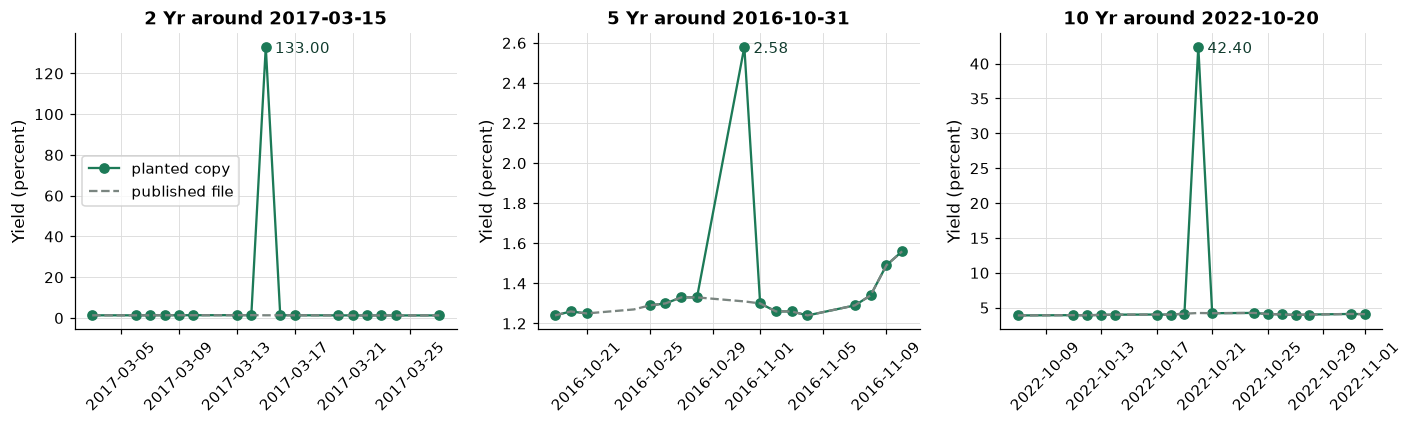

In [25]:
# each suspect in the middle of eight rows either side; the true values held back are dashed
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (date, column) in zip(axes, suspects):
    at = planted.index.get_loc(date)
    window = planted.index[at - 8:at + 9]
    ax.plot(window, planted.loc[window, column], marker="o", color=plotkit.GREEN, label="planted copy")
    ax.plot(window, treasury.loc[window, column], linestyle="--", color=plotkit.GREY, label="published file")
    ax.annotate(f"{planted.at[date, column]:.2f}", xy=(date, planted.at[date, column]), xytext=(6, -4),
                textcoords="offset points", fontsize=10, color=plotkit.GREEN_DARK)
    ax.set_title(f"{column} around {date.date()}")
    ax.set_ylabel("Yield (percent)")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(loc="center left")
fig.tight_layout()
plt.show()

* Each wrong value is one point far off the line, with its neighbours on the line. The y axis shows how far: a yield in bp is a hundred times its value in percent, and a slipped decimal ten times. The 5 Yr's is the subtle one: 30 Yr yields are a plausible number, just in the wrong column.

Q. Compare the planted copy with the second source wherever both have a value.

In [26]:
# where both sources have a value, do they agree to within half a basis point?
both = planted.loc[backup.index, backup.columns]
gap_bp = (both - backup).abs() * 100
disagree = gap_bp.where(gap_bp > 0.5).stack().dropna()
print(f"cells where both have a value: {int(both.notna().sum().sum()):,}; they disagree on {len(disagree)}")
for (date, column), bp in disagree.items():
    print(f"{column} on {date.date()}: planted {planted.at[date, column]:.2f}, second source "
          f"{backup.at[date, column]:.2f}, {bp:,.0f} bp apart")

cells where both have a value: 2,874; they disagree on 1
10 Yr on 2022-10-20: planted 42.40, second source 4.24, 3,816 bp apart


* 2,874 cells in both sources, one disagreement: the 10 Yr on 2022-10-20. A second source finds a wrong value without any rule about its shape, but only on the dates and columns it covers. The 2 Yr's bad print is from 2017, before the desk's sheet starts, so only the jump rule found it.

Q. Fix the 10 Yr by hand with `.loc`, on a copy.

In [27]:
# one wrong value fixed by hand, on a copy: .loc[row, column] = the second source's value
by_hand = planted.copy()
print(f"before: {by_hand.loc[wrong_10y, '10 Yr']:.2f}")
by_hand.loc[wrong_10y, "10 Yr"] = backup.loc[wrong_10y, "10 Yr"]
print(f"after: {by_hand.loc[wrong_10y, '10 Yr']:.2f}")

before: 42.40
after: 4.24


* `.loc[row, column] = value` sets one cell. It works, and it leaves no trace: in a month nobody can say what the cell held before, who changed it, or on what source. For one cell in a notebook that is fine; for a dataset others use, it is not.

Q. Write the three corrections as a table instead: date, column, new value, source.

In [28]:
# the three corrections as a table: one row per cell, with the new value and where it came from
corrections = pd.DataFrame({
    "date": [wrong_5y, wrong_2y, wrong_10y],
    "column": ["5 Yr", "2 Yr", "10 Yr"],
    # the 5 Yr held the 30 Yr's yield and no checked 5 Yr value is to hand, so the correction blanks it
    "value": [np.nan, planted.at[wrong_2y, "2 Yr"] / 100, backup.at[wrong_10y, "10 Yr"]],
    "source": ["blanked: the 30 Yr's yield in the 5 Yr column", "printed in bp: divided by 100",
               "the desk's end-of-day sheet"],
})
print(corrections.to_string())

        date column  value                                         source
0 2016-10-31   5 Yr    NaN  blanked: the 30 Yr's yield in the 5 Yr column
1 2017-03-15   2 Yr   1.33                  printed in bp: divided by 100
2 2022-10-20  10 Yr   4.24                    the desk's end-of-day sheet


* The 5 Yr's value is `NaN` on purpose: the cell is known to be wrong and no checked 5 Yr value is to hand, so the honest correction is a blank, filled later like any other gap.

Q. Apply the table with `DataFrame.update`, on a copy. Did every cell change?

In [29]:
# DataFrame.update writes the corrections table into a copy, cell by cell, matched on date and column
updated = planted.copy()
updated.update(corrections.pivot(index="date", columns="column", values="value"))
for date, column in zip(corrections["date"], corrections["column"]):
    print(f"{column} on {date.date()}: {planted.at[date, column]:.2f} became {updated.at[date, column]:.2f}")

5 Yr on 2016-10-31: 2.58 became 2.58
2 Yr on 2017-03-15: 133.00 became 1.33
10 Yr on 2022-10-20: 42.40 became 4.24


* Two of three. The 5 Yr still holds 2.58. **The trap:** `update` skips every `NaN` in what it is given, by design: it never writes a blank. So a correction that means "this value is wrong, blank it" is silently ignored, and the wrong value stays in the table with no error and no warning. The pivot also changed the table's shape to a grid, and that loses the source column.

Q. Add `apply_corrections` to `tskit.py`, with its tests.

In [30]:
%%writefile -a tskit.py


def apply_corrections(frame: pd.DataFrame, corrections: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply a table of corrections to a dated frame; return the corrected copy and a log of every change.

    Inputs: frame, dated rows, one column per series; corrections, a DataFrame with the columns date, column,
    value, source: one row per cell to set. value may be NaN, to blank a value known to be wrong (DataFrame.update
    skips a NaN, so it can never blank a cell).
    Output: (corrected, log). corrected is a copy of frame; the input is not changed. log is a DataFrame with the
    columns date, column, old, new, source: one row per cell whose value changed, in the order of corrections.
    A correction that leaves a cell as it was (the same number, or blank to blank) is not a change and is not
    logged.
    Raises ValueError if corrections lacks one of its four columns, if a date or a column is not in frame, or if
    one cell is corrected twice.
    """
    _check_dated(frame.index, "frame")
    needed = ["date", "column", "value", "source"]
    missing = [name for name in needed if name not in corrections.columns]
    if missing:
        raise ValueError(f"corrections needs the columns {needed}; missing {missing}")
    dates = pd.DatetimeIndex(corrections["date"])
    unknown_dates = dates[~dates.isin(frame.index)]
    if len(unknown_dates):
        raise ValueError(f"dates not in frame: {[str(d.date()) for d in unknown_dates]}")
    unknown_columns = sorted(set(corrections["column"]) - set(frame.columns))
    if unknown_columns:
        raise ValueError(f"columns not in frame: {unknown_columns}")
    cells = list(zip(dates, corrections["column"]))
    if len(set(cells)) != len(cells):
        raise ValueError("a cell is corrected twice: one row per cell")
    corrected = frame.copy()
    log = []
    for (date, column), value, source in zip(cells, corrections["value"], corrections["source"]):
        old = corrected.at[date, column]
        # blank to blank, or the same number, is not a change
        if (pd.isna(old) and pd.isna(value)) or old == value:
            continue
        corrected.at[date, column] = value
        log.append({"date": date, "column": column, "old": old, "new": value, "source": source})
    return corrected, pd.DataFrame(log, columns=["date", "column", "old", "new", "source"])

Appending to tskit.py


* It refuses a corrections table without its four columns, a date or a column the frame does not have, and the same cell twice: each would be a silent mistake. A `NaN` in `value` blanks the cell, which is the case `update` misses.
* It works on a copy (`frame.copy()`) and returns the copy with the log, so the original stays available to compare with.
* A correction that changes nothing (the same number, or blank to blank) is not logged: the log holds changes only.

In [31]:
%%writefile -a test_tskit.py


def test_apply_corrections_logs_and_copies():
    frame = dated_frame()
    day = frame.index[3]
    corrections = pd.DataFrame({"date": [day, frame.index[4]], "column": ["b", "b"],
                                "value": [9.99, frame.at[frame.index[4], "b"]], "source": ["desk", "desk"]})
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert corrected.at[day, "b"] == 9.99 and frame.at[day, "b"] != 9.99
    # the second correction changes nothing, so only the first is logged
    assert log[["column", "new", "source"]].values.tolist() == [["b", 9.99, "desk"]]
    assert log["old"].iloc[0] == frame.at[day, "b"]


def test_apply_corrections_blanks_where_update_does_not():
    frame = dated_frame()
    day = frame.index[8]
    corrections = pd.DataFrame({"date": [day], "column": ["b"], "value": [np.nan], "source": ["desk"]})
    updated = frame.copy()
    updated.update(corrections.pivot(index="date", columns="column", values="value"))
    assert updated.at[day, "b"] == frame.at[day, "b"]
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert np.isnan(corrected.at[day, "b"]) and len(log) == 1 and np.isnan(log["new"].iloc[0])


def test_apply_corrections_refusals():
    frame = dated_frame()
    good = {"date": [frame.index[0]], "column": ["b"], "value": [4.0], "source": ["desk"]}
    with pytest.raises(ValueError, match="missing"):
        tskit.apply_corrections(frame, pd.DataFrame(good).drop(columns="source"))
    with pytest.raises(ValueError, match="dates not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"date": [pd.Timestamp("2024-01-06")]}))
    with pytest.raises(ValueError, match="columns not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"column": ["c"]}))
    with pytest.raises(ValueError, match="twice"):
        tskit.apply_corrections(frame, pd.concat([pd.DataFrame(good)] * 2))

Appending to test_tskit.py


* `test_apply_corrections_blanks_where_update_does_not` runs `update` on the same table first and asserts the cell did **not** change, then asserts `apply_corrections` blanked it. The trap is in the tests, so nobody "simplifies" the function back to `update`.

Q. Reload the module and run the tests.

In [32]:
# the file changed, so reload before using the new function
importlib.reload(tskit)
print(f"apply_corrections in tskit: {hasattr(tskit, 'apply_corrections')}")

apply_corrections in tskit: True


In [33]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......                                                                  [100%]
7 passed in 2.34s



* `7 passed`: the 4 from section 1.2 and today's three new ones.

Q. Apply the corrections table with `apply_corrections`.

In [34]:
# the same table through apply_corrections: a corrected copy, and a log of every cell it changed
corrected, log = tskit.apply_corrections(planted, corrections)
print(log.to_string())
print(f"the 5 Yr on {wrong_5y.date()} is now blank: {bool(np.isnan(corrected.at[wrong_5y, '5 Yr']))}")

        date column     old   new                                         source
0 2016-10-31   5 Yr    2.58   NaN  blanked: the 30 Yr's yield in the 5 Yr column
1 2017-03-15   2 Yr  133.00  1.33                  printed in bp: divided by 100
2 2022-10-20  10 Yr   42.40  4.24                    the desk's end-of-day sheet
the 5 Yr on 2016-10-31 is now blank: True


* Three rows in the log, each with the old value, the new one, and its source. The 5 Yr's new value is blank: the cell is now a gap like any other, and section 1.5 fills it.

Q. Fill blanks from the second source with `combine_first`, then make the same fills through `apply_corrections`, so they reach the log too.

In [35]:
# combine_first: take the planted copy's value where it has one, and the second source's where it is blank
combined = corrected.combine_first(backup)[corrected.columns]
filled_cells = corrected[backup.columns].isna() & combined[backup.columns].notna()
print(f"cells filled from the second source: {int(filled_cells.sum().sum())}")

# the same fills as a corrections table, so they reach the log too: the second source's value for each blank
from_backup = backup.where(filled_cells.loc[backup.index]).stack().dropna().rename("value").reset_index()
from_backup = from_backup.rename(columns={"level_1": "column"})
from_backup["source"] = "second source (combine_first)"
repaired, backup_log = tskit.apply_corrections(corrected, from_backup[["date", "column", "value", "source"]])
print(f"the same as combine_first: {repaired.equals(combined)}")
change_log = pd.concat([log, backup_log], ignore_index=True)

cells filled from the second source: 4
the same as combine_first: True


* `combine_first` keeps every value of the first table and takes the second's only where the first is blank: 4 blank days of the 2 Yr and 10 Yr from 2021 on. It is one line, and like `update` it leaves no record. The cell turns the same fills into a corrections table (`where` keeps the second source's value only on those cells, `stack` makes one row per cell) and applies it, and the result is identical to `combine_first`'s.
* `[corrected.columns]` keeps the tenors in their order: `combine_first` returns the union of both tables' columns.

Q. Show the whole change log.

In [36]:
# dates as text, so the table reads cleanly
plotkit.styled(change_log.assign(date=change_log["date"].dt.strftime("%Y-%m-%d")), [],
               "The change log: every cell the corrections and the second source changed", fmt="{:.2f}")

,date,column,old,new,source
0,2016-10-31,5 Yr,2.58,,blanked: the 30 Yr's yield in the 5 Yr column
1,2017-03-15,2 Yr,133.00,1.33,printed in bp: divided by 100
2,2022-10-20,10 Yr,42.40,4.24,the desk's end-of-day sheet
3,2022-06-17,2 Yr,,3.17,second source (combine_first)
4,2023-02-06,10 Yr,,3.63,second source (combine_first)
5,2023-12-05,2 Yr,,4.57,second source (combine_first)
6,2024-09-18,2 Yr,,3.61,second source (combine_first)


* 7 changes, each traceable: three corrections and 4 fills from the second source. A blank in `new` is a cell blanked on purpose. This is the table to save and commit with the data, and section "Save the Day with Git" does.

Q. Save the change log as a CSV file in the work folder.

In [37]:
# the change log as a file: dates as text, LF line endings, so Git shows a real change as one line
change_log.to_csv("changes.csv", index=False, date_format="%Y-%m-%d", float_format="%.6g", lineterminator="\n")

print((work / "changes.csv").read_text(encoding="utf-8"))

date,column,old,new,source
2016-10-31,5 Yr,2.58,,blanked: the 30 Yr's yield in the 5 Yr column
2017-03-15,2 Yr,133,1.33,printed in bp: divided by 100
2022-10-20,10 Yr,42.4,4.24,the desk's end-of-day sheet
2022-06-17,2 Yr,,3.17,second source (combine_first)
2023-02-06,10 Yr,,3.63,second source (combine_first)
2023-12-05,2 Yr,,4.57,second source (combine_first)
2024-09-18,2 Yr,,3.61,second source (combine_first)



## 1.5 Filling Gaps in a Series

**How it works.** A fill puts a number in a blank cell from the values around it in the same column. **Forward fill** (`ffill`, Course 3's) copies the last value before the blank down into it. **Backfill** (`bfill`) copies the first value after the blank up into it. **Linear interpolation** draws a straight line between the value before the run and the value after it and reads each blank off the line, spacing the blanks by rows; with `method="time"` it spaces them by the dates' distance in days, so a weekend or a holiday inside the run counts. You control how far a fill reaches (`limit`, the most blanks filled in a row) and where it may fill (`limit_area`: anywhere, only between two values, or only outside them). What comes out is a table with fewer blanks, and every filled cell is a guess.

Q. Read every setting of `interpolate`, `ffill`, and `bfill`, with the defaults taken from the installed pandas.

In [38]:
import inspect

# the defaults are read from the installed pandas, never typed
defaults = {name: parameter.default for name, parameter in inspect.signature(pd.DataFrame.interpolate).parameters.items()}
fill_defaults = {name: parameter.default for name, parameter in inspect.signature(pd.DataFrame.ffill).parameters.items()}
settings = pd.DataFrame([
    ("interpolate", "method", defaults["method"], "how a blank is filled from the values around it: "
     "linear counts rows, time counts days", "time weights each blank by its distance in days", "yes"),
    ("interpolate", "limit", defaults["limit"], "the most blanks filled in a row in one run",
     "a larger limit fills more of a long run; None fills all of it", "yes"),
    ("interpolate", "limit_area", defaults["limit_area"], "None fills anywhere; inside fills only between two values; "
     "outside fills only before the first or after the last", "inside never extends a series past its ends", "yes"),
    ("interpolate", "limit_direction", defaults["limit_direction"], "which way a run is filled: forward, backward, "
     "or both (None means forward for linear and time)", "both or backward also fills before a series starts", "no"),
    ("interpolate", "axis", defaults["axis"], "0 fills down each column (along the dates); 1 fills across a row",
     "1 fills across tenors on one date", "no"),
    ("interpolate", "inplace", defaults["inplace"], "True changes the frame itself and returns None",
     "False keeps the original to compare with", "no"),
    ("ffill and bfill", "limit", fill_defaults["limit"], "the most blanks filled in a row in one run",
     "a larger limit carries a value further", "yes"),
    ("ffill and bfill", "limit_area", fill_defaults["limit_area"], "None, inside, or outside, as for interpolate",
     "inside keeps a value from being carried past the series' ends", "yes"),
], columns=["function", "setting", "default", "what it controls", "raising or widening it", "tune first"])
settings["default"] = settings["default"].map(repr)

plotkit.styled(settings.set_index(["function", "setting"]), [],
               "Every setting of interpolate, ffill, and bfill: the defaults read from the installed pandas")

<styled table: Every setting of interpolate, ffill, and bfill: the defaults read from the installed pandas>

* Three settings matter, marked "tune first": the `method`, the `limit`, and the `limit_area`. The rest are housekeeping: `axis` stays 0 (fill along the dates), `inplace` stays False (keep the original to compare with), and `limit_direction` stays at its default, forward, because backward reaches into the past from the future.
* The default `limit` is `None`: no limit. A plain `interpolate()` fills a 20-day outage as readily as a single day. Sections 1.5 and 1.7 show what that does.

Q. Which planted blanks are still open after the corrections, and how many are there in each group?

In [39]:
# the cells that were planted blank and are still blank: their true values were held back in `treasury`
targets = repaired.isna() & treasury.notna()
in_outage = pd.DataFrame(False, index=repaired.index, columns=repaired.columns)
in_outage.loc[outage_dates] = True
groups = {"single days": targets & ~in_outage, "the 20-day outage": targets & in_outage}
for group, mask in groups.items():
    print(f"{group}: {int(mask.sum().sum())} cells to fill")

single days: 52 cells to fill
the 20-day outage: 240 cells to fill


* 52 single blank days (55 planted, 4 filled from the second source, plus the 5 Yr blanked by its correction) and 240 outage cells (20 dates in 12 tenors). Their true values are in `treasury`, so every fill can be scored.

Q. Fill the same table four ways.

In [40]:
# a demonstration: four ways to fill the same blanks, the backfill among them to show what it does
fills = {
    "ffill": repaired.ffill(),
    "bfill": repaired.bfill(),
    "interpolate (linear)": repaired.interpolate(method="linear"),
    "interpolate (time)": repaired.interpolate(method="time"),
}
for method, filled in fills.items():
    print(f"{method}: {int(filled.isna().sum().sum()):,} cells still blank")

ffill: 5,432 cells still blank
bfill: 0 cells still blank
interpolate (linear): 5,432 cells still blank
interpolate (time): 5,432 cells still blank


* Three methods leave the same number of cells blank: the before-start cells of the late starters, which they leave alone. The backfill leaves none: it filled every one of them too, which is the first thing wrong with it.
* The cell says `demonstration` in its first comment. The course's build refuses a backfill anywhere else, because it moves a later value onto an earlier date.

Q. Draw every method side by side against the true values: the 10 Yr across the outage, and across one single blank day.

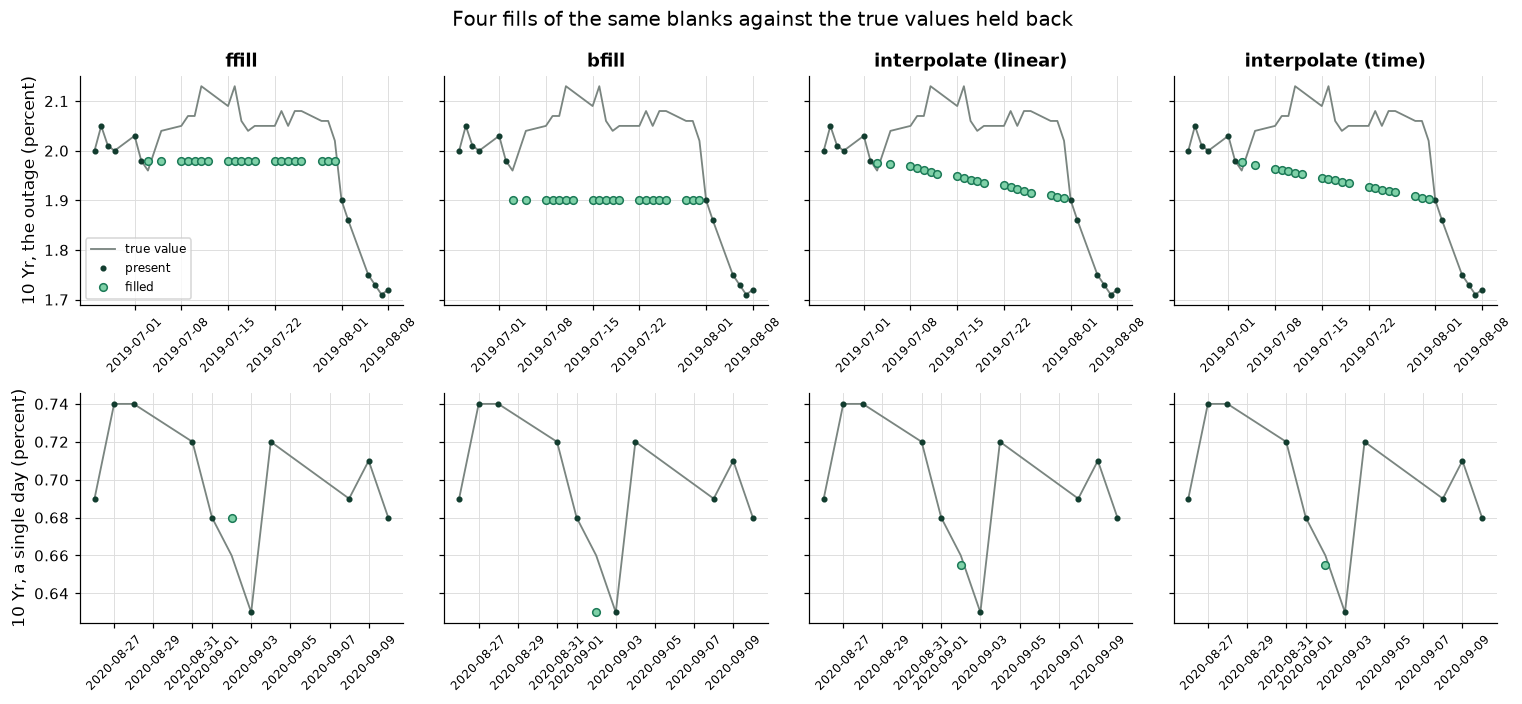

In [41]:
# top row: the 10 Yr across the outage; bottom row: across one single blank day of the 10 Yr
single_10y = groups["single days"]["10 Yr"]
blank_days = single_10y[single_10y].index
# the single blank day whose two neighbours differ most, so the four fills land in different places
spread = [abs(repaired["10 Yr"].iloc[at + 1] - repaired["10 Yr"].iloc[at - 1]) for at in map(repaired.index.get_loc, blank_days)]
single_day = blank_days[int(np.argmax(spread))]
at_out, at_single = planted.index.get_loc(outage_dates[0]), planted.index.get_loc(single_day)
windows = [planted.index[at_out - 6:at_out + 26], planted.index[at_single - 5:at_single + 6]]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharey="row")
for column, (method, filled) in enumerate(fills.items()):
    for row, window in enumerate(windows):
        ax = axes[row, column]
        was_blank = repaired.loc[window, "10 Yr"].isna()
        ax.plot(window, treasury.loc[window, "10 Yr"], color=plotkit.GREY, linewidth=1.2, label="true value")
        ax.plot(window[~was_blank], repaired.loc[window, "10 Yr"][~was_blank], "o", color=plotkit.GREEN_DARK,
                markersize=3, label="present")
        ax.plot(window[was_blank], filled.loc[window, "10 Yr"][was_blank], "o", color=plotkit.GREEN_LIGHT,
                markeredgecolor=plotkit.GREEN, markersize=5, label="filled")
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        if row == 0:
            ax.set_title(method)
    axes[0, 0].set_ylabel("10 Yr, the outage (percent)")
    axes[1, 0].set_ylabel("10 Yr, a single day (percent)")
axes[0, 0].legend(fontsize=8, loc="lower left")
fig.suptitle("Four fills of the same blanks against the true values held back")
fig.tight_layout()
plt.show()

* How to read it: the grey line is what the Treasury published; dark points are the values present in the repaired copy; pale points are what each method put in the blanks. Across the outage (top row), `ffill` holds the 10 Yr flat at its last value for 20 rows and `bfill` holds it flat at the first value after; both interpolations draw a straight line between the two ends. None of them follows the grey line's wiggles: no fill can recover what happened during 20 days nobody recorded. Across one day (bottom row), the interpolations land close to the true value and the two copies land a day's move away.

Q. Score each method on the filled cells: its error against the true values, in bp, for single days and for the outage.

In [42]:
# each method's error on the filled cells, in bp, against the true values held back in `treasury`
rows = []
for method, filled in fills.items():
    error = ((filled - treasury).abs() * 100).to_numpy()
    row = {"method": method}
    for group, mask in groups.items():
        values = error[mask.to_numpy()]
        row[f"{group}: MAE (bp)"] = values.mean()
        row[f"{group}: largest (bp)"] = values.max()
    # cells the method filled where the published file has no value: dates before a series started
    row["filled before a start"] = int((filled.notna() & treasury.isna()).sum().sum())
    rows.append(row)
errors = pd.DataFrame(rows).set_index("method")
print(errors.round(2).to_string())

                      single days: MAE (bp)  single days: largest (bp)  the 20-day outage: MAE (bp)  the 20-day outage: largest (bp)  filled before a start
method                                                                                                                                                     
ffill                                  2.67                       14.0                         6.97                            20.00                      0
bfill                                  3.25                       24.0                        10.97                            23.00                   5432
interpolate (linear)                   2.12                       12.0                         8.25                            18.43                      0
interpolate (time)                     2.04                       12.0                         8.35                            18.73                      0


In [43]:
plotkit.styled(errors, [column for column in errors.columns if "bp" in column],
               "Fill error against the true values held back, in bp: lowest marked", higher_is_better=False, fmt="{:.2f}")

,single days: MAE (bp),single days: largest (bp),the 20-day outage: MAE (bp),the 20-day outage: largest (bp),filled before a start
method,,,,,
ffill,2.67,14.00,6.97,20.00,0
bfill,3.25,24.00,10.97,23.00,"5,432"
interpolate (linear),2.12,12.00,8.25,18.43,0
interpolate (time),2.04,12.00,8.35,18.73,0


* On single days the interpolations miss by 2.04 bp on average against 2.67 bp for `ffill`: a line through both ends lands about halfway between two days' values. Across the outage the order changes: the forward fill's average error is the lowest (6.97 bp against 8.25 for the linear line), because the largest move of those weeks came on the first date after the outage, so the line leaned toward that date's value for all 20 days while the yields themselves sat higher (the top row of the figure shows it). Its worst miss, 20.00 bp, is larger than either interpolation's. Across 20 days no method is reliably closer; another outage could put them in another order. Linear and time interpolation differ wherever a weekend or a holiday sits inside the run, because `time` counts calendar days: across this outage, which holds four weekends and the July 4th holiday, their two lines for the 10 Yr are at most 0.46 bp apart.
* The last column is the backfill's real cost: 5,432 cells filled before a series started, a 1.5 Month yield in 2015 copied back from 2025.
* The lowest error does not make a method the right one. Section 1.6 shows why the interpolations' low error is exactly the problem when the series is scored.

Q. Draw the errors as bars.

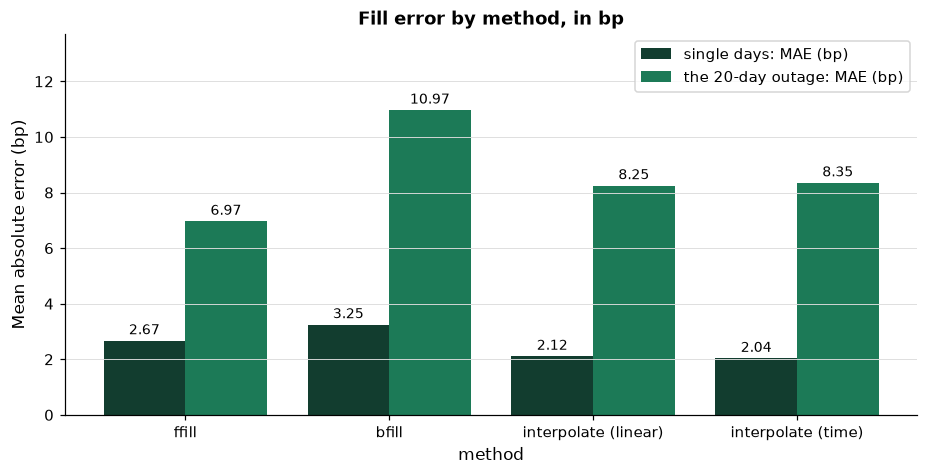

In [44]:
# mean absolute error by method, for each group of blanks, in bp
fig, ax = plt.subplots(figsize=(10, 4.5))
plotkit.bars(errors[["single days: MAE (bp)", "the 20-day outage: MAE (bp)"]], "Fill error by method, in bp",
             "Mean absolute error (bp)", ax=ax, fmt="{:.2f}")
ax.set_ylim(0, errors["the 20-day outage: MAE (bp)"].max() * 1.25)
plt.show()

* The outage bars are several times the single-day bars for every method. A fill across one day is a small guess; across 20 days, a large one.

Q. Fill the 2 Mo around the date it starts three ways: backfill, interpolation in both directions, and interpolation inside only.

In [45]:
# a demonstration: three fills of the 2 Mo around the date it starts
start_2mo = treasury["2 Mo"].first_valid_index()
area_fills = {
    "bfill": repaired["2 Mo"].bfill(),
    'interpolate(limit_direction="both")': repaired["2 Mo"].interpolate(method="time", limit_direction="both"),
    'interpolate(limit_area="inside")': repaired["2 Mo"].interpolate(method="time", limit_area="inside"),
}
for name, filled in area_fills.items():
    print(f"{name}: {int(filled.loc[:start_2mo].iloc[:-1].notna().sum())} cells filled before {start_2mo.date()}")

bfill: 949 cells filled before 2018-10-16
interpolate(limit_direction="both"): 949 cells filled before 2018-10-16
interpolate(limit_area="inside"): 0 cells filled before 2018-10-16


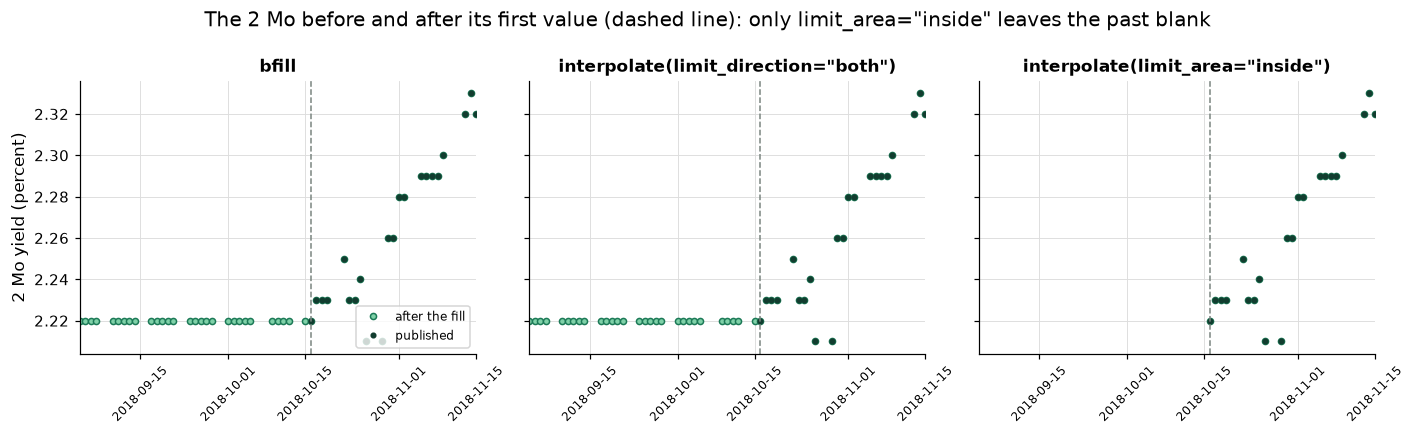

In [46]:
# the 2 Mo around its first date: what each fill puts before the series existed
window = repaired.loc[start_2mo - pd.Timedelta(days=45):start_2mo + pd.Timedelta(days=30)].index
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, filled) in zip(axes, area_fills.items()):
    ax.plot(window, filled.loc[window], "o", color=plotkit.GREEN_LIGHT, markeredgecolor=plotkit.GREEN, markersize=4,
            label="after the fill")
    ax.plot(window, treasury.loc[window, "2 Mo"], "o", color=plotkit.GREEN_DARK, markersize=3, label="published")
    ax.axvline(start_2mo, color=plotkit.GREY, linestyle="--", linewidth=1)
    ax.set_xlim(window[0], window[-1])
    ax.set_title(name, fontsize=11)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0].set_ylabel("2 Mo yield (percent)")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("The 2 Mo before and after its first value (dashed line): only limit_area=\"inside\" leaves the past blank")
fig.tight_layout()
plt.show()

* `bfill` and `limit_direction="both"` each put 949 values before 2018-10-16: a flat line of the 2 Mo's first yield, back to 2015, for a series that did not exist. `limit_area="inside"` fills only blanks with a value on both sides, so the past stays blank. Pass `limit_area="inside"` whenever a fill runs on a table that holds late starters.

Q. Sweep the limit: for each limit, how many outage cells a fill reaches, and its error on the cells it filled.

In [47]:
# the outage's cells only: how many each limit fills, and the error on the cells it fills, in bp
outage_mask = groups["the 20-day outage"].to_numpy()
limits = [1, 2, 3, 5, 10, 15, 20]
sweep = []
for limit in limits:
    for method, filled in (("ffill", repaired.ffill(limit=limit)),
                           ("interpolate (time)", repaired.interpolate(method="time", limit=limit, limit_area="inside"))):
        error = ((filled - treasury).abs() * 100).to_numpy()[outage_mask]
        done = ~np.isnan(error)
        sweep.append({"limit": limit, "method": method, "cells filled": int(done.sum()), "MAE (bp)": error[done].mean()})
sweep = pd.DataFrame(sweep)
print(sweep.pivot(index="limit", columns="method", values="MAE (bp)").round(2).to_string())

method  ffill  interpolate (time)
limit                            
1        1.83                1.82
2        4.12                4.45
3        5.08                5.74
5        5.72                6.65
10       6.84                7.77
15       6.66                7.70
20       6.97                8.35


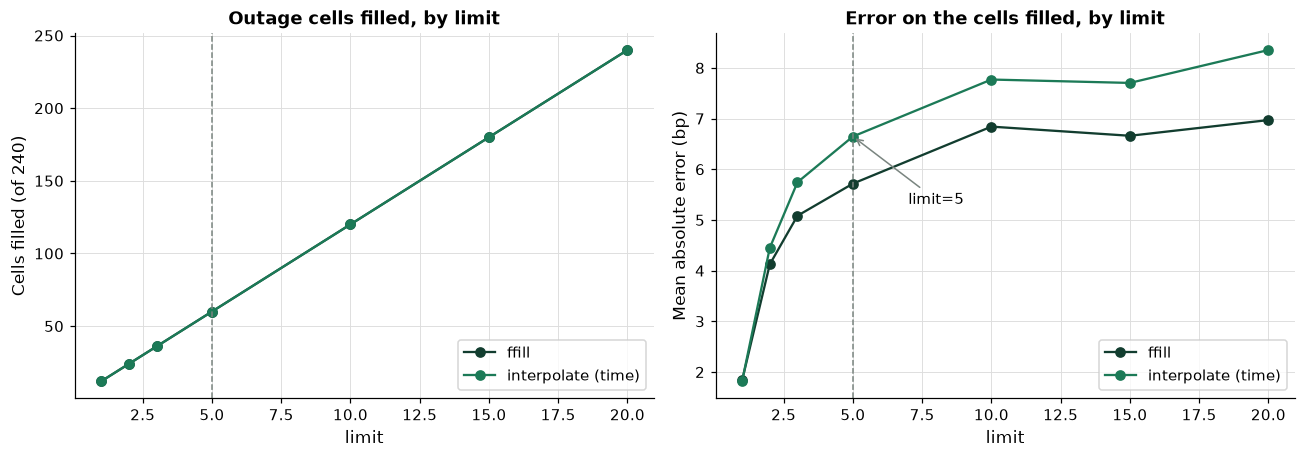

In [48]:
# left: the outage cells filled as the limit grows; right: the error on those cells, in bp
wide_filled = sweep.pivot(index="limit", columns="method", values="cells filled")
wide_error = sweep.pivot(index="limit", columns="method", values="MAE (bp)")
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.3))
plotkit.line_compare(wide_filled, "Outage cells filled, by limit", "Cells filled (of 240)", ax=left)
plotkit.line_compare(wide_error, "Error on the cells filled, by limit", "Mean absolute error (bp)", ax=right)
for ax in (left, right):
    ax.axvline(5, color=plotkit.GREY, linestyle="--", linewidth=1)
right.annotate("limit=5", xy=(5, wide_error.loc[5].max()), xytext=(7, wide_error.loc[5].max() * 0.8),
               fontsize=10, arrowprops={"arrowstyle": "->", "color": plotkit.GREY})
fig.tight_layout()
plt.show()

* How to read it: as the limit grows, each fill reaches further into the outage (left) and its error on what it filled rises (right), because each extra day is further from a known value: from 1.83 bp at `limit=1` to 6.84 bp at `limit=10` for the forward fill, and close to that for the longer limits; `limit=20` fills every outage cell. Choose the limit from what a stale value may cost, not from the error, which is never known in real work: section 1.7 uses 5.

## 1.6 Which Fill When

The error table ranks the interpolations first on single days. That ranking answers the wrong question for most uses. Which fill is right depends on what the series is for:

* **Forward fill, for a quote you could have traded on.** On a blank day, the last value you had was the last one before it. A forward-filled series holds only what was known on each date, so a risk report or a walk-forward score built on it uses nothing from the future. Its error is the honest cost of the gap.
* **Interpolation, for a missing point on a curve or a description of history.** A chart of the 10 Yr over ten years, or a 5 Yr point between the 3 Yr and the 7 Yr on one date (Exercise 2), reads better with a line through the gap, and the line uses both ends because it is a description, not a decision.
* **Never a backfill or an interpolation into anything scored walk-forward.** Both use a value from after the gap. A model scored on a series filled that way is scored with help from the future, and its score improves for a reason that has nothing to do with the model.

Q. Show that last point with the simplest walk-forward rule: the last value carried forward. Score it on the dates right after each planted blank, after each fill.

In [49]:
# the first present date after each planted blank, in the full tenors
blank_before = targets[full_tenors].shift(1, fill_value=False) & ~targets[full_tenors]
# a score is kept only on dates that hold a value in the repaired copy, as real scoring would be
has_value = repaired[full_tenors].notna().to_numpy()
scored = {"the file as published (no gap)": treasury[full_tenors]} | {method: fills[method][full_tenors]
                                                                       for method in ["ffill", "interpolate (time)", "bfill"]}
gain = []
for name, series in scored.items():
    # the last value carried forward: the value on the row before, scored against the true value on the date
    error = ((treasury[full_tenors] - series.shift(1)).abs() * 100).to_numpy()
    gain.append({"filled with": name, "dates after a gap: MAE (bp)": np.nanmean(error[blank_before.to_numpy()]),
                 "every date with a value: MAE (bp)": np.nanmean(error[has_value])})
gain = pd.DataFrame(gain).set_index("filled with")
print(f"dates right after a planted blank: {int(blank_before.sum().sum())}")
print(gain.round(3).to_string())

dates right after a planted blank: 63
                                dates after a gap: MAE (bp)  every date with a value: MAE (bp)
filled with                                                                                   
the file as published (no gap)                        4.651                              3.169
ffill                                                 4.873                              3.170
interpolate (time)                                    1.930                              3.164
bfill                                                 0.000                              3.160


In [50]:
plotkit.styled(gain, list(gain.columns), "The last value carried forward, scored after each fill: error against the "
               "true values in bp, lowest marked", higher_is_better=False, fmt="{:.3f}")

,dates after a gap: MAE (bp),every date with a value: MAE (bp)
filled with,,
the file as published (no gap),4.651,3.169
ffill,4.873,3.170
interpolate (time),1.930,3.164
bfill,0.000,3.160


* On the 63 dates right after a planted blank, the backfill scores exactly 0.000 bp: the value it carried into the blank was that date's own value, so the "last value" is the answer. The time interpolation scores 1.93 bp, better than the 4.65 bp the rule scores on the file with no gap at all. A gap cannot make a rule better than having the data. The forward fill scores 4.87 bp: worse, and honest, because on those dates a desk really did have only the value before the gap.
* Over every date the differences are small (3.160, 3.169, 3.170 bp), because the gaps touch few dates. A false gain that small is easy to miss and easy to believe. That is why the course's build refuses a backfill outside a demonstration cell.

Q. Draw the false gain.

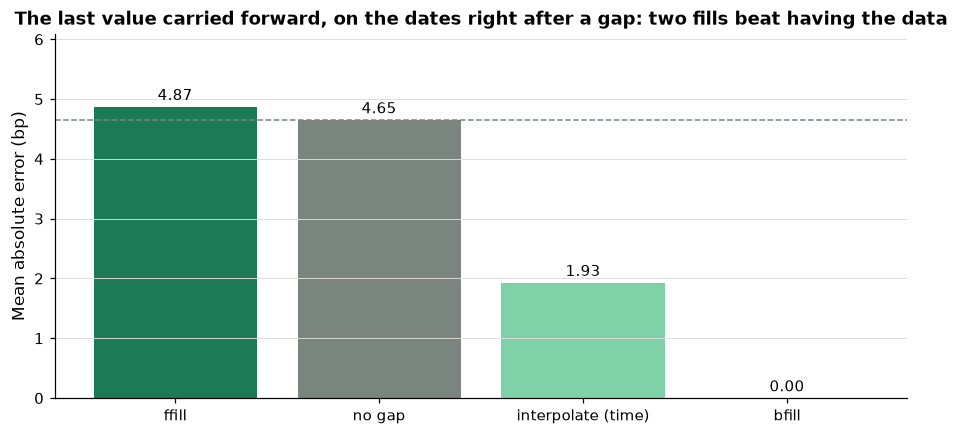

In [51]:
# the scores on the dates after a gap, against the score with no gap: below the line is better than having the data
fig, ax = plt.subplots(figsize=(10, 4.3))
order = ["ffill", "the file as published (no gap)", "interpolate (time)", "bfill"]
values = gain.loc[order, "dates after a gap: MAE (bp)"]
bars = ax.bar(["ffill", "no gap", "interpolate (time)", "bfill"], values.to_numpy(),
              color=[plotkit.GREEN, plotkit.GREY, plotkit.GREEN_LIGHT, plotkit.GREEN_LIGHT])
ax.bar_label(bars, fmt="{:.2f}", fontsize=10, padding=2)
ax.axhline(values["the file as published (no gap)"], color=plotkit.GREY, linestyle="--", linewidth=1)
ax.set_ylim(0, values.max() * 1.25)
ax.set_ylabel("Mean absolute error (bp)")
ax.set_title("The last value carried forward, on the dates right after a gap: two fills beat having the data")
ax.grid(axis="x", visible=False)
plt.show()

* Any bar below the dashed line is a score better than the file with no gap: a sign that the fill has used a later value. Keep the picture in mind for day 2, where every model is scored this way.

## 1.7 A Long Outage

**How it works.** `limit=` caps how many blanks in a row a fill may fill: within each run, the first `limit` blanks are filled and the rest stay blank. For a forward fill that means a value is carried at most `limit` trading days; past that, the series admits it does not know. The setting is the limit, chosen from how stale a value may be before it misleads (five trading days here: one week). What comes out is a table whose short gaps are filled and whose long gaps are shorter but still there, and a check downstream can see them. A limit does not skip a long run: it fills its first rows. To leave a long run entirely blank, mark it with `gap_runs` first (Exercise 5 needs exactly that).

Q. Forward fill with `limit=5`. What does `gap_report` show for the full tenors, and what runs are left in the 10 Yr?

In [52]:
# a forward fill that stops after 5 blanks in a row: a quote at most five trading days stale
limited = repaired.ffill(limit=5)
print(tskit.gap_report(limited[full_tenors])[["blank_inside", "longest_inside"]].T.to_string())
print(tskit.gap_runs(limited["10 Yr"]).to_string())

column          1 Mo  3 Mo  6 Mo  1 Yr  2 Yr  3 Yr  5 Yr  7 Yr  10 Yr  20 Yr  30 Yr
blank_inside      15    15    15    15    15    15    15    15     15     15     15
longest_inside    15    15    15    15    15    15    15    15     15     15     15
       start        end  rows    kind
0 2019-07-11 2019-07-31    15  inside


* Every single blank day is filled, and in each full tenor one run of 15 blanks is left: the outage after its first five days, from 2019-07-11 to 2019-07-31.

Q. Draw the 10 Yr across the outage: the true values, a forward fill with no limit, and one with `limit=5`.

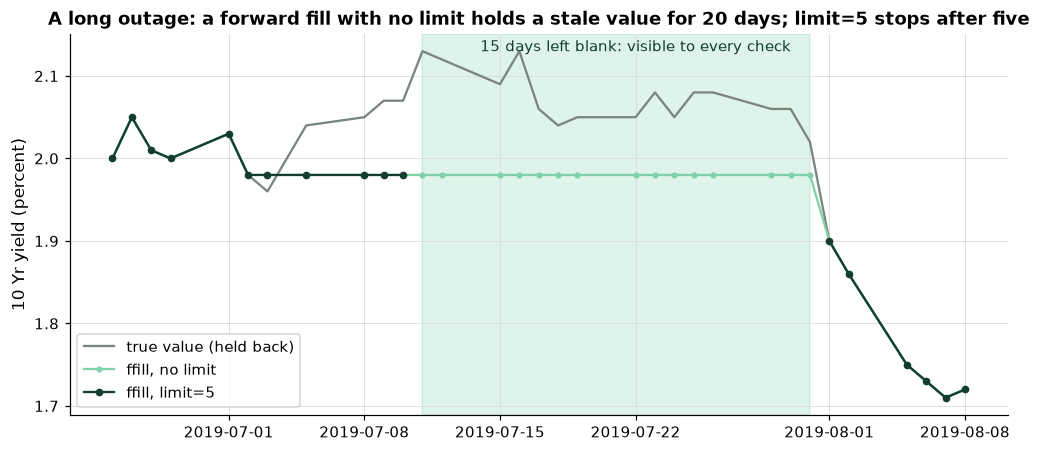

In [53]:
# the outage window of the 10 Yr; the blank rows left by limit=5 are shaded
window = planted.index[planted.index.get_loc(outage_dates[0]) - 6:planted.index.get_loc(outage_dates[-1]) + 7]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(window, treasury.loc[window, "10 Yr"], color=plotkit.GREY, linewidth=1.5, label="true value (held back)")
ax.plot(window, fills["ffill"].loc[window, "10 Yr"], "o-", color=plotkit.GREEN_LIGHT, markersize=3,
        label="ffill, no limit")
ax.plot(window, limited.loc[window, "10 Yr"], "o-", color=plotkit.GREEN_DARK, markersize=4, label="ffill, limit=5")
left_blank = limited.loc[window, "10 Yr"].isna()
ax.axvspan(window[left_blank][0], window[left_blank][-1], color=plotkit.GREEN_LIGHT, alpha=0.25)
ax.annotate("15 days left blank: visible to every check", xy=(window[left_blank][7], treasury["10 Yr"].loc[window].max()),
            fontsize=10, color=plotkit.GREEN_DARK, ha="center")
ax.set_ylabel("10 Yr yield (percent)")
ax.set_title("A long outage: a forward fill with no limit holds a stale value for 20 days; limit=5 stops after five")
ax.legend(loc="lower left")
plt.show()

* With no limit, the 10 Yr sits at its July 2 value for four weeks while the true yield moves away from it. With `limit=5` the stale value lasts a week and then the line breaks, and a break in a line is something every reader and every check can see.

Q. A model on day 2 cannot take a blank. Write a check that stops before scoring a column with blank dates.

In [54]:
# a check that stops: a column that will be scored must hold no blank date
scored_10y = limited["10 Yr"]
blank_dates = int(scored_10y.isna().sum())
if blank_dates:
    raise ValueError(f"the 10 Yr has {blank_dates} blank dates, from {scored_10y[scored_10y.isna()].index[0].date()}: "
                     "drop them from the dates you score, or fill them on purpose and say how")

ValueError: the 10 Yr has 15 blank dates, from 2019-07-11: drop them from the dates you score, or fill them on purpose and say how

* The check stops with the count and the first blank date. A gap that stays visible is a gap that someone has to decide about, which is the point.

Q. Decide: score only the dates that hold a value, and say how many were left out.

In [55]:
# score only dates with a value, and say how many were left out
scored_10y = limited["10 Yr"]
kept = scored_10y.dropna()
print(f"10 Yr dates kept: {len(kept):,} of {len(scored_10y):,}; left out: {len(scored_10y) - len(kept)}, all in the outage")

10 Yr dates kept: 2,925 of 2,940; left out: 15, all in the outage


* 2,925 dates kept, 15 left out. Leaving dates out of a score is fine when it is said; a score that quietly includes 15 invented days is not.

## Excel Side by Side

Excel has no function that fills a gap from its neighbours, and nothing that writes a change log: both are built from formulas, and that makes each step visible. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-20) on the planted 10 Yr: the dates in column A as Excel dates, the planted 10 Yr in percent in B2:B2941 of a sheet named `curve`, and the second source on a sheet named `backup`. Formulas that work on a range were entered as dynamic-array formulas (`Formula2`).

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| Count the blanks | `planted["10 Yr"].isna().sum()` | `=COUNTBLANK(B2:B2941)` | 25 |
| Weekdays in the span | `len(pd.bdate_range(first, last))` | `=NETWORKDAYS(A2,A2941)` | 3,066 |
| Weekdays with no row | `len(absent)` | `=NETWORKDAYS(A2,A2941)-ROWS(A2:A2941)` | 126 |
| Forward fill | `planted["10 Yr"].ffill()` | `=IF(B3="",C2,B3)` in C3, filled down | equal within 1e-12 |
| Linear interpolation, by rows | `interpolate(method="linear")` | `=$B$1127+($B$1148-$B$1127)*(ROW()-ROW($B$1127))/(ROW($B$1148)-ROW($B$1127))` | equal within 1e-12 |
| Linear interpolation, by dates | `interpolate(method="time")` | `=$B$1127+($B$1148-$B$1127)*($A1128-$A$1127)/($A$1148-$A$1127)` | equal within 1e-12 |
| Fill from a second source | `corrected.combine_first(backup)` | `=IF(G2="",XLOOKUP(A2,backup!$A$2:$A$1440,backup!$B$2:$B$1440,""),G2)` | equal on every row |
| A jump that comes straight back | `undone` | `=IFERROR(AND(ABS(I4)>50,ABS(I3)>50,SIGN(I4)=-SIGN(I3)),FALSE)` | TRUE on 2022-10-21 only |

**Counting.** `COUNTBLANK` counts the empty cells in a range: Python's `isna().sum()`. `NETWORKDAYS` counts the Mondays to Fridays from the first date to the last, both included, which is `pd.bdate_range`; subtract `ROWS`, the dates the file has, and what is left is the 126 absent weekdays.

**Forward fill is one IF.** C2 is the first value. In C3, `IF(B3="",C2,B3)` says: if today's cell is empty, take the filled value from the row above, else today's own. Filled down, a blank inherits the last value through any number of blanks in a row, exactly as `ffill` with no limit. A limit would need a count of blanks in a row beside it, which is one more column.

**Interpolation by hand.** For a run of blanks between a known value in row 1127 and the next in row 1148, each blank's value is the first value plus the change between the two, times how far along the run it is. By rows, "how far along" is `ROW()` against the two rows' numbers: `method="linear"`. By dates, it is the cell's date in A against the two dates: `method="time"`, which counts the July 4th holiday inside this run as the day it is. The `$` signs hold the two ends fixed while the formula is filled down the run.

**A second source is a lookup.** `XLOOKUP` finds today's date in the backup sheet's dates and returns its 10 Yr; with `""` as its fourth argument it returns an empty text when the date is not there. Wrapped in `IF(B2="",...,B2)` it takes the backup only where the planted cell is empty, which is `combine_first`.

**The jump rule.** With the change in bp in D (blank where either day is blank), `AND` asks the three questions of section 1.4 on each row; `IFERROR` turns the rows where a change is blank into FALSE, as pandas' comparisons with `NaN` are False.

Q. Do Excel's values equal Python's?

In [56]:
# Excel's results, from the course's Excel check, beside Python's
excel_side = pd.DataFrame({
    "Excel": [25, 3066, 126, 0.0,
              0.0, 0.0],
    "Python": [int(planted["10 Yr"].isna().sum()), len(weekdays), len(absent), 0.0, 0.0, 0.0],
}, index=pd.Index(["blank cells", "weekdays in the span", "weekdays with no row", "forward fill: largest gap",
                    "interpolation by rows: largest gap", "interpolation by dates: largest gap"], name="Check"))
excel_side["equal within 1e-12"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-12
plotkit.styled(excel_side, [], "Excel beside Python on the planted 10 Yr: counts, and the largest gap between the two",
               fmt="{:.0f}")

,Excel,Python,equal within 1e-12
Check,,,
blank cells,25,25,True
weekdays in the span,3066,3066,True
weekdays with no row,126,126,True
forward fill: largest gap,0,0,True
interpolation by rows: largest gap,0,0,True
interpolation by dates: largest gap,0,0,True


* Every count is equal, and the forward fill and both interpolations match pandas within 1e-12 on every row the Excel check compared (2,940 for the forward fill, the 20 outage rows for each interpolation). The lookup column equals `combine_first`'s 10 Yr on every row, the 10 Yr's one fill from the second source included, and the jump rule flagged only 2022-10-21, the day after the 10 Yr's slipped decimal.

## Save the Day with Git

Today's Git step puts the change log under version control beside the code: a correction to a dataset is a change like any other, and it deserves a commit with a message.

Q. Start a repository in the work folder.

In [57]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [58]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5b_01_bar0tubv and nowhere else


Q. Tell Git which files never to track, then see what it would track.

In [59]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [60]:
# ?? marks a file Git does not track yet
!git -C "{work}" status --short

?? .gitignore
?? changes.csv
?? mlkit.py
?? plotkit.py
?? test_tskit.py
?? treasury_par_yields.csv
?? tskit.py


* The Treasury file is the course's data and `plotkit.py` the course's helpers: both stay untracked. The commit takes the code.

Q. Commit the code: `mlkit.py`, `tskit.py`, and its tests.

In [61]:
!git -C "{work}" add .gitignore mlkit.py tskit.py test_tskit.py
!git -C "{work}" commit -q -m "Day 1: tskit with gap_report, gap_runs, and apply_corrections"
!git -C "{work}" show --stat --format=%s HEAD

Day 1: tskit with gap_report, gap_runs, and apply_corrections

 .gitignore    |   3 +
 mlkit.py      | 568 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_tskit.py |  85 +++++++++
 tskit.py      | 126 +++++++++++++
 4 files changed, 782 insertions(+)


Q. Commit the change log in its own commit, so its history is its own.

In [62]:
!git -C "{work}" add changes.csv
!git -C "{work}" commit -q -m "Day 1: the change log of the planted copy"
!git -C "{work}" log --oneline

8f270e9 Day 1: the change log of the planted copy
d95833a Day 1: tskit with gap_report, gap_runs, and apply_corrections


* Two commits: the code, then the log. If a later correction changes a row of `changes.csv`, `git diff` shows that one line, and `git log` says when and why.

## Bring It Home

Start `tskit.py` in your own `my_bondmath` folder, beside `mlkit.py` and `ensemblekit.py`. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Create `tskit.py` and paste the code of today's two `tskit.py` cells (sections 1.2 and 1.4), without their first lines, one after the other. Do the same for the two `test_tskit.py` cells in a new `test_tskit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_tskit.py
```

The last line says `7 passed`.

**Step 4.** Commit.

```powershell
git add tskit.py test_tskit.py
git commit -m "Day 1: tskit with gap_report, gap_runs, and apply_corrections"
```

## You Can Now

* Tell an absent row, a blank cell, a series not started yet, and a wrong value apart, and count each.
* Find every gap with `isna`, a heatmap of blanks over time, `gap_runs`, `gap_report`, and `first_valid_index`.
* Check absent dates against a holiday calendar, and say why a calendar is a starting point, not the answer.
* Find a wrong value by its shape and by a second source, and correct it with a corrections table and a change log (`apply_corrections`), knowing why `update` cannot blank a cell.
* Fill gaps with `ffill`, `bfill`, and `interpolate`, read every setting, and choose `limit` and `limit_area` on purpose.
* Say which fill suits a quote you could have traded on and which suits a description, and spot a score that a fill improved falsely.
* Stop a fill at a limit, keep a long gap visible, and stop before scoring a column that still has blanks.

Next, day 2: frequency, lags, and the naive baselines, the scores every later model is judged against.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the Treasury file, finds the absent weekdays, plants the same problems as section 1.1, applies the same corrections and second source as section 1.4, makes the forward fill with `limit=5` of section 1.7, and defines `check`, a small function that marks your answers.

In [63]:
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
weekdays = pd.bdate_range(treasury.index[0], treasury.index[-1])
absent = weekdays.difference(treasury.index)
# every planted problem comes from one seeded generator, so every run plants the same ones
rng = np.random.default_rng(SEED)
planted = treasury.copy()

# 1. a 20-day outage: 20 rows in a row in which every tenor is blank (rows 1,100 to 1,399 fall in 2019 and 2020)
outage_start = int(rng.integers(1_100, 1_400))
outage_dates = planted.index[outage_start:outage_start + 20]
planted.loc[outage_dates] = np.nan

# 2. single blank days: five dates in each tenor that has a value on every date, away from the outage and the ends
full_tenors = [column for column in treasury.columns if treasury[column].notna().all()]
away = np.r_[10:outage_start - 10, outage_start + 30:len(planted) - 10]
for column in full_tenors:
    rows = rng.choice(away, size=5, replace=False)
    planted.iloc[rows, planted.columns.get_loc(column)] = np.nan

# 3. three wrong values in present rows: another tenor's yield, a yield in bp, and a slipped decimal point
wrong_5y = planted.index[int(rng.choice(np.flatnonzero(planted.index.year == 2016)))]
wrong_2y = planted.index[int(rng.choice(np.flatnonzero(planted.index.year == 2017)))]
wrong_10y = planted.index[int(rng.choice(np.flatnonzero(planted.index.year == 2022)))]
planted.at[wrong_5y, "5 Yr"] = treasury.at[wrong_5y, "30 Yr"]
planted.at[wrong_2y, "2 Yr"] = treasury.at[wrong_2y, "2 Yr"] * 100
planted.at[wrong_10y, "10 Yr"] = treasury.at[wrong_10y, "10 Yr"] * 10

# 4. a second source: the desk's own end-of-day sheet, kept for the 2 Yr and the 10 Yr from 2021 on
backup = treasury.loc["2021-01-04":, ["2 Yr", "10 Yr"]].copy()

print(f"outage: {outage_dates[0].date()} to {outage_dates[-1].date()}, {len(outage_dates)} rows")
print(f"single blank days: 5 in each of the {len(full_tenors)} full tenors")
print(f"wrong values: 5 Yr on {wrong_5y.date()}, 2 Yr on {wrong_2y.date()}, 10 Yr on {wrong_10y.date()}")
print(f"second source: {list(backup.columns)}, {len(backup):,} rows from {backup.index[0].date()}")

# the three corrections as a table: one row per cell, with the new value and where it came from
corrections = pd.DataFrame({
    "date": [wrong_5y, wrong_2y, wrong_10y],
    "column": ["5 Yr", "2 Yr", "10 Yr"],
    # the 5 Yr held the 30 Yr's yield and no checked 5 Yr value is to hand, so the correction blanks it
    "value": [np.nan, planted.at[wrong_2y, "2 Yr"] / 100, backup.at[wrong_10y, "10 Yr"]],
    "source": ["blanked: the 30 Yr's yield in the 5 Yr column", "printed in bp: divided by 100",
               "the desk's end-of-day sheet"],
})
print(corrections.to_string())
corrected, log = tskit.apply_corrections(planted, corrections)
combined = corrected.combine_first(backup)[corrected.columns]
filled_cells = corrected[backup.columns].isna() & combined[backup.columns].notna()
from_backup = backup.where(filled_cells.loc[backup.index]).stack().dropna().rename("value").reset_index()
from_backup = from_backup.rename(columns={"level_1": "column"})
from_backup["source"] = "second source (combine_first)"
repaired, backup_log = tskit.apply_corrections(corrected, from_backup[["date", "column", "value", "source"]])
limited = repaired.ffill(limit=5)


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

outage: 2019-07-03 to 2019-07-31, 20 rows
single blank days: 5 in each of the 11 full tenors
wrong values: 5 Yr on 2016-10-31, 2 Yr on 2017-03-15, 10 Yr on 2022-10-20
second source: ['2 Yr', '10 Yr'], 1,439 rows from 2021-01-04
        date column  value                                         source
0 2016-10-31   5 Yr    NaN  blanked: the 30 Yr's yield in the 5 Yr column
1 2017-03-15   2 Yr   1.33                  printed in bp: divided by 100
2 2022-10-20  10 Yr   4.24                    the desk's end-of-day sheet


### Exercise 1

Q. How many of the absent weekdays are Mondays? Store the count in **ex1_mondays**. (`DatetimeIndex.dayofweek` is 0 for a Monday.) Why would so many holidays fall on one weekday?

In [64]:
ex1_mondays = ...

In [65]:
check("Exercise 1 absent Mondays", ex1_mondays, 75)

Exercise 1 absent Mondays: not attempted yet


### Exercise 2

Q. Fill the 5 Yr on 2016-10-31, the cell blanked by its correction, from the same date's 3 Yr and 7 Yr instead of from the days around it: a straight line in maturity, `y3 + (y7 - y3) * (5 - 3) / (7 - 3)`. Store its error against the true 5 Yr (in `treasury`), in bp, in **ex2_curve_error_bp**. Is it closer than the time interpolation of section 1.5?

In [66]:
ex2_curve_error_bp = ...

In [67]:
check("Exercise 2 the 5 Yr from the curve", ex2_curve_error_bp, 0.0)

Exercise 2 the 5 Yr from the curve: not attempted yet


### Exercise 3

Q. Add a function to your module. `count_filled(before, after)` returns how many cells are blank in `before` and hold a value in `after`, and refuses two frames with different dates or columns with `ValueError`. Write the docstring first. Add `test_count_filled_hand`, which uses `dated_frame` (a forward fill fills 2 of its blanks and a backfill 4) and checks the refusal. Run pytest, reload the module, and store `tskit.count_filled(repaired, limited)` in **ex3_filled**.

Write the function in the cell that starts with `%%writefile -a tskit.py` and the test in the one that starts with `%%writefile -a test_tskit.py`, and run each of those cells once.

In [68]:
%%writefile -a tskit.py


# Exercise 3: write count_filled(before, after) below this line

Appending to tskit.py


In [69]:
%%writefile -a test_tskit.py


# Exercise 3: write test_count_filled_hand() below this line

Appending to test_tskit.py


In [70]:
# run pytest, reload the module, then use your function
ex3_filled = ...

In [71]:
check("Exercise 3 cells filled with limit=5", ex3_filled, 112)

Exercise 3 cells filled with limit=5: not attempted yet


### Exercise 4

Q. Lower the jump rule's threshold from 50 bp to 25 bp and run it on the **published** file, `treasury`. How many cells does it flag? Store the count in **ex4_flags**. Are they wrong prints?

In [72]:
ex4_flags = ...

In [73]:
check("Exercise 4 flags at 25 bp", ex4_flags, 3)

Exercise 4 flags at 25 bp: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that fills the short gaps in a series before it is scored, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Fill the short gaps in a dated series of yields in percent, before the series is scored.

    A run of at most max_rows blank rows inside the series is filled by interpolation on the dates
    (method="time"). A longer run stays blank, every row of it, so a scored date is never invented.
    Rows before the series starts stay blank.
    Returns a new Series; the input is not changed.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a Series of the right length, and contains one bug.

In [74]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def fill_short_gaps(series, max_rows=3):
    """Fill the short gaps in a dated series of yields in percent, before the series is scored.

    A run of at most max_rows blank rows inside the series is filled by interpolation on the dates
    (method="time"). A longer run stays blank, every row of it, so a scored date is never invented.
    Rows before the series starts stay blank.
    Returns a new Series; the input is not changed.
    """
    # interpolate on the dates, so a weekend counts as the days it is; interpolate returns a new Series
    filled = series.interpolate(method="time")
    return filled

Q. Before you run the next cell: the 10 Yr in `repaired` has single blank days and the 20-day outage. How many of the outage's 20 dates will hold a value after `fill_short_gaps`, and how calm will the filled outage look?

In [75]:
# how many outage dates got a value, and the spread of the daily changes across the outage, filled against true
filled = fill_short_gaps(repaired["10 Yr"])
span = treasury.index[treasury.index.get_loc(outage_dates[0]) - 1:treasury.index.get_loc(outage_dates[-1]) + 2]
print(f"outage dates with a value: {int(filled.loc[outage_dates].notna().sum())} of {len(outage_dates)}")
print(f"daily changes across the outage: standard deviation {(filled.loc[span].diff() * 100).std():.2f} bp filled, "
      f"{(treasury.loc[span, '10 Yr'].diff() * 100).std():.2f} bp true")

outage dates with a value: 20 of 20
daily changes across the outage: standard deviation 0.22 bp filled, 4.34 bp true


Q. Test the function against its docstring before you trust it: every short run filled, every long run left blank.

In [76]:
# the test, written from the docstring before the code is trusted
ten_year = repaired["10 Yr"]
filled = fill_short_gaps(ten_year)
for _, run in tskit.gap_runs(ten_year).iterrows():
    kept = int(filled.loc[run["start"]:run["end"]].notna().sum())
    if run["rows"] > 3:
        # a long run stays blank, every row of it
        assert kept == 0, (f"{kept} of the {run['rows']} blank rows from {run['start'].date()} to "
                           f"{run['end'].date()} were filled; a run longer than 3 rows must stay blank")
    else:
        assert kept == run["rows"], f"the short run on {run['start'].date()} was not filled"
print("every short run filled, every long run left blank")

AssertionError: 20 of the 20 blank rows from 2019-07-03 to 2019-07-31 were filled; a run longer than 3 rows must stay blank

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the number of blank dates left in the fixed function's 10 Yr, `int(fill_short_gaps(repaired["10 Yr"]).isna().sum())`, in **ex5_blank**.

In [77]:
# fix the function above and run the test again, then store the answer
ex5_blank = ...

In [78]:
check("Exercise 5 blank dates left by the fixed function", ex5_blank, 20)

Exercise 5 blank dates left by the fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```